LIBRARY VERSIONS / SETTINGS
python 3.13.15 | numpy 2.1.3 | pandas 2.3.3 | scipy 1.16.3 | sklearn 1.6.1
cpu cores: 4 | QUICK_MODE: False
xgboost 3.4.1
lightgbm 4.6.0
shap 0.52.0

DATA
USING CSV: /kaggle/input/datasets/ritwikb3/heart-disease-cleveland/Heart_disease_cleveland_new.csv
Rows loaded 303 -> after exact-duplicate removal 303
Missing values (total): 0
Class balance: {0: 164, 1: 139} | positive class = 1 (dataset's own coding, not flipped)
Train 242 | Test 61 (same split as Part 1)

RankSumSelector (K=4, train split) selected: ['thal', 'ca', 'exang', 'cp']
Paper's Table 13 (Cleveland):                      ['thalach', 'oldpeak', 'cp', 'chol']
Overlap: ['cp']

PHASE 1+2 - HOLD-OUT EVALUATION: DEFAULT vs TUNED (tuned on the TRAINING split only)
[    10s] Logistic Regression  default_all  test_acc=0.8525 auc=0.9426
[    10s] Logistic Regression  default_k4   test_acc=0.8361 auc=0.9031
[    13s] Logistic Regression  tuned_all    test_acc=0.8525 auc=0.9426 best={'class_weight': None, 

Background dataset has 242 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=242 when initializing the masker.


              model  avg_rank  rank_gap  mean_diff_vs_best  p_wilcoxon  p_holm              note
      Random Forest      3.10      0.00             0.0000         NaN     NaN best average rank
            XGBoost      3.70      0.60             0.0020      0.9414  0.9414 within Nemenyi CD
           LightGBM      4.20      1.10             0.0043      0.1523  0.5273 within Nemenyi CD
        Naive Bayes      4.25      1.15             0.0066      0.2754  0.5508 within Nemenyi CD
Logistic Regression      4.95      1.85             0.0085      0.1309  0.5273 within Nemenyi CD
                KNN      5.00      1.90             0.0077      0.1055  0.5273 within Nemenyi CD
                SVM      5.35      2.25             0.0089      0.0098  0.0684 within Nemenyi CD
     Neural Network      5.45      2.35             0.0114      0.0840  0.5039 within Nemenyi CD
      Decision Tree      9.00      5.90             0.0876      0.0020  0.0156         beyond CD
   [main CSV saved: 535 rows -

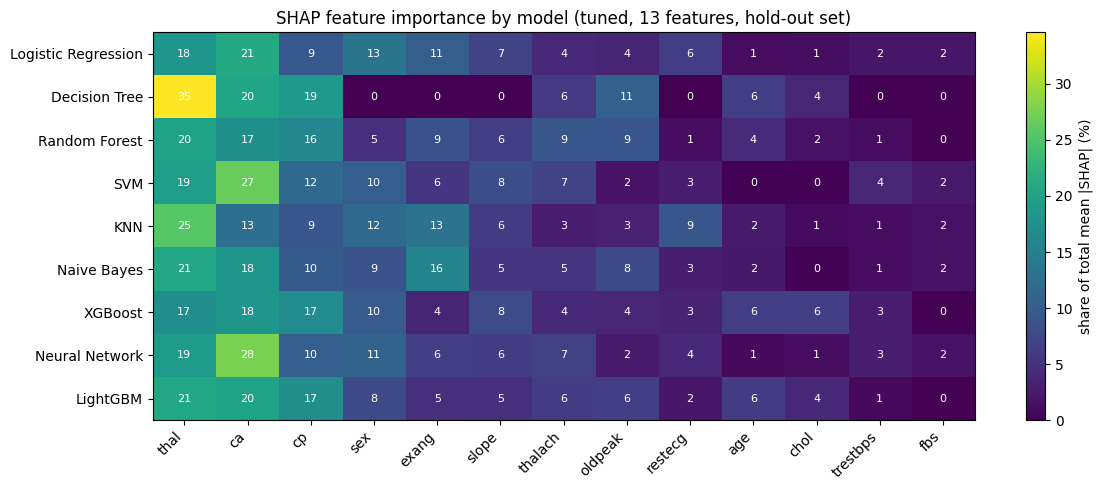

Saved: /kaggle/working/shap_importance_heatmap.png

Mean share of SHAP importance across models (%):
thal        21.7
ca          20.2
cp          13.3
sex          8.6
exang        7.6
slope        5.8
thalach      5.6
oldpeak      5.4
restecg      3.5
age          3.3
chol         2.2
trestbps     1.8
fbs          1.1

Detailed SHAP plots for the best model by nested-CV AUC (tuned_all): Random Forest


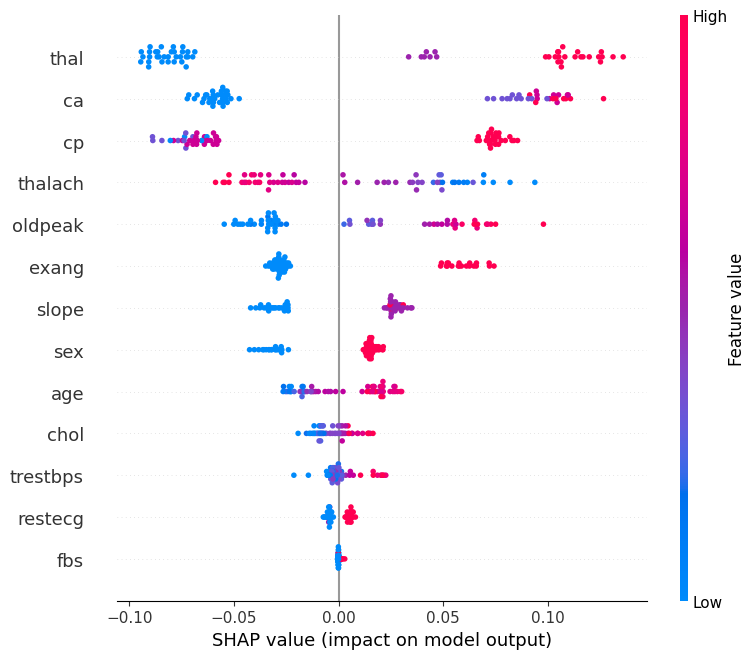

Saved: /kaggle/working/shap_summary_Random_Forest.png


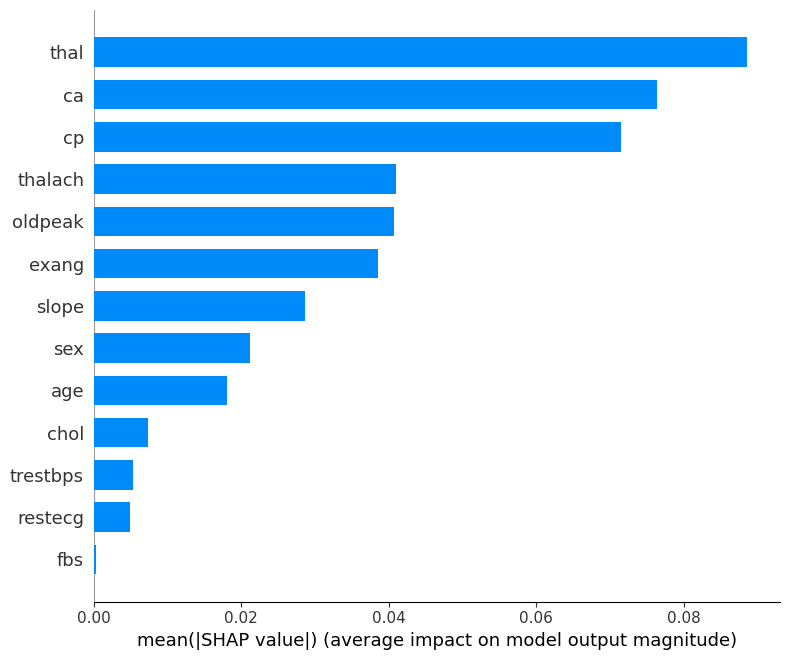

Saved: /kaggle/working/shap_bar_Random_Forest.png


<Figure size 640x480 with 0 Axes>

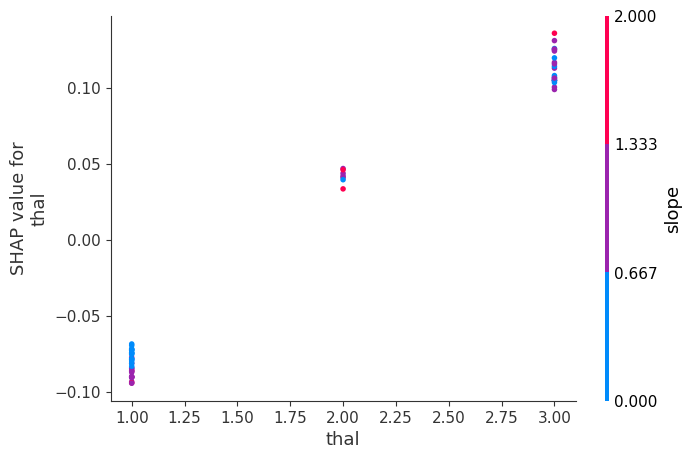

Saved: /kaggle/working/shap_dependence_Random_Forest_thal.png

Top-4 by SHAP (Random Forest): ['thal', 'ca', 'cp', 'thalach']
RankSumSelector top-4 (train split): ['thal', 'ca', 'exang', 'cp']
Paper's Table 13 four features:      ['thalach', 'oldpeak', 'cp', 'chol']
SHAP vs RankSum overlap: ['ca', 'cp', 'thal'] | SHAP vs paper overlap: ['cp', 'thalach']
Note: SHAP shows what the fitted model relies on; it is not a causal / clinical statement, and with 61 explained rows the ranking is noisy.


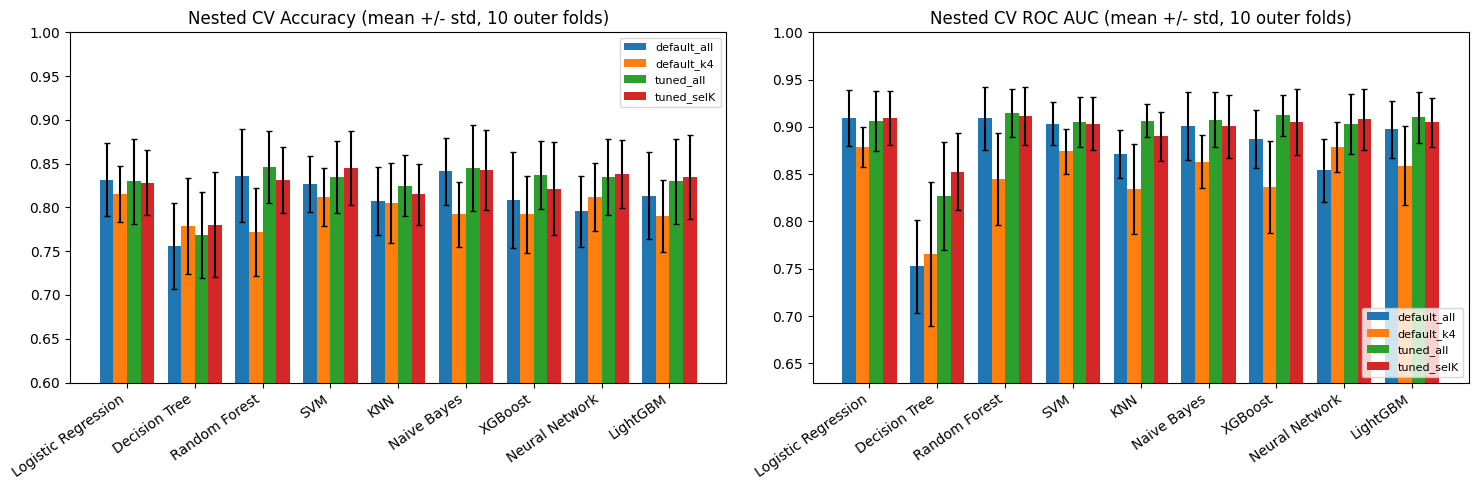

Saved: /kaggle/working/nestedcv_default_vs_tuned.png


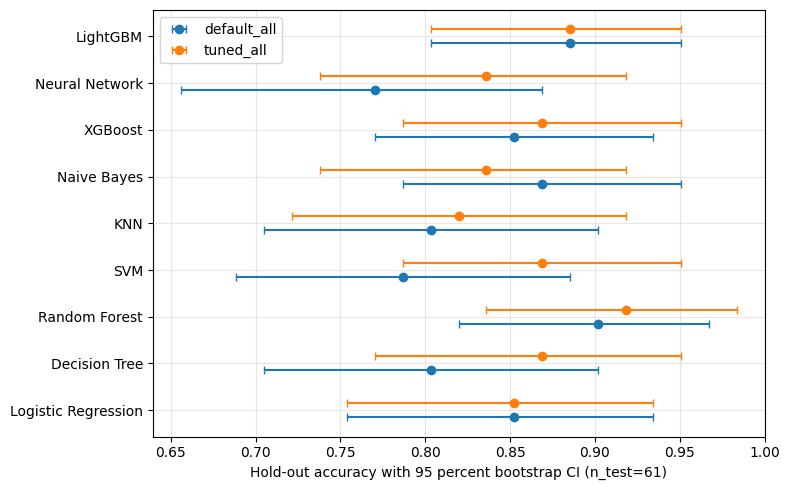

Saved: /kaggle/working/holdout_accuracy_ci.png

SUMMARY
Paired comparisons significant after Holm correction (alpha=0.05): 4
                                analysis  metric         model  mean_diff  p_holm
       Tuning effect (selected features) roc_auc Random Forest     0.0669  0.0400
       Tuning effect (selected features) roc_auc   Naive Bayes     0.0372  0.0374
Selection effect (default settings, K=4) roc_auc Random Forest    -0.0645  0.0324
Selection effect (default settings, K=4) roc_auc           SVM    -0.0288  0.0274

Highest nested-CV mean AUC: Random Forest / tuned_all = 0.9143 +/- 0.0253. Check the Friedman / Nemenyi / Holm tables before calling any model 'best'.

Caveats: the hold-out test has only 61 rows (95 percent CI half-width roughly 7-9 accuracy points); nested-CV folds overlap in training data so p-values are approximate and power is low (N=10 folds). Search spaces, K_GRID and SHAP settings are my own assumptions.

REFERENCE ONLY: the paper reports about 90.16% 

In [1]:
# =============================================================================
# Cleveland heart disease - PART 2: baseline vs OPTIMISED models + STATISTICS + SHAP (XAI)
# (continues the Narasimhan & Victor (2025) replication attempt; Part 1 = cleveland_replication.py)
#
# WHAT THIS SCRIPT DOES
#  1. BASELINE: the same default models/pipelines/split as Part 1 (so numbers can be compared).
#  2. OPTIMISATION: hyper-parameter search per model on the TRAINING split only
#     (5-fold stratified inner CV, RandomizedSearchCV, scoring = ROC AUC). The test split is
#     never used for tuning. In the feature-selection variant the number of selected
#     features K is ALSO tuned inside the inner CV.
#  3. HOLD-OUT EVALUATION on the untouched 20% test split + bootstrap 95% CIs.
#  4. NESTED CROSS-VALIDATION on all de-duplicated rows (repeated stratified 5-fold outer loop,
#     tuning repeated inside every outer-training fold) = the main evidence; the 61-row test
#     split is not.
#  5. STATISTICS on the paired nested-CV fold scores: Nadeau-Bengio corrected paired t-test,
#     Friedman + Nemenyi critical difference, Holm-corrected Wilcoxon vs the best-ranked model,
#     paired bootstrap CIs on the hold-out set.
#  6. SHAP (explainable AI) for every tuned model (13 features) on the hold-out set, with detailed
#     plots for the best model (by nested-CV AUC) and a cross-model importance heat-map.
#
# OUTPUT: ONE main CSV  /kaggle/working/cleveland_main_results.csv
#   The first column "record_type" says what each row is:
#     run_info          settings / data facts (item, value)
#     model_summary     one row per (model, variant): hold-out metrics, bootstrap CIs, nested-CV mean/std,
#                       best hyper-parameters, features used
#     nestedcv_fold     one row per (model, variant, outer fold)
#     stat_test         every statistical test (analysis, comparison, metric, p_value, p_holm, ...)
#     selector_rank     RankSumSelector rank-sum per feature (training split)
#     shap_importance   mean |SHAP| per (model, feature) on the hold-out set
#   (PNG figures are also saved in /kaggle/working/.)
#   The CSV is re-saved after every stage, so a crash late in the run cannot lose earlier results.
#
# HONESTY NOTES
#  - Tuning on ~240 rows often gives small or no gains; the script reports whatever it finds.
#  - Inner-CV best scores are optimistic by construction; only nested-CV / hold-out numbers
#    are reported as performance.
#  - Tests on 10 correlated CV folds have LOW POWER and approximate p-values.
#  - SHAP explains what the MODEL uses, not medical causality; with 61 explained rows the
#    rankings are noisy, and SHAP scales differ between model types (so use the % columns to compare).
#  - No tuning on test data, no seed search (RANDOM_STATE = 42 throughout).
# =============================================================================

import os
os.environ["PYTHONWARNINGS"] = "ignore"        # also silences joblib worker processes

import glob
import time
import platform
import traceback
import warnings
from math import prod
from functools import partial

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
from scipy import stats
from scipy.stats import rankdata

import sklearn
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.feature_selection import SelectKBest, chi2, f_classif, mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     RepeatedStratifiedKFold, RandomizedSearchCV)
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier

warnings.filterwarnings("ignore")

# ----------------------------------------------------------------------------
# Configuration
# ----------------------------------------------------------------------------
RANDOM_STATE = 42
QUICK_MODE = False             # True = fast smoke test (fewer repeats / iterations)
K_FEATURES = 4                 # paper-based assumption, used by the default_k4 variant
TEST_SIZE = 0.20
TUNE_SCORING = "roc_auc"       # smoother / less noisy than accuracy on ~240 rows
INNER_FOLDS = 5
OUTER_FOLDS = 5
OUTER_REPEATS = 2              # 5x2 = 10 paired outer folds
N_ITER = 20                    # random-search budget per model (capped at grid size)
N_BOOT = 1000                  # bootstrap resamples on the hold-out set
K_GRID = [3, 4, 5, 6, 8, 10]   # K values searched in the tuned_selK variant
N_JOBS = -1
ALPHA = 0.05                   # Nemenyi table below is for alpha = 0.05
RUN_SHAP = True
SHAP_BACKGROUND = 15           # background rows for KernelExplainer (SVM / KNN / NB / MLP)
SHAP_NSAMPLES = 300            # KernelExplainer samples per row (approximation, stated in CSV)

if QUICK_MODE:
    OUTER_REPEATS, N_ITER, N_BOOT, SHAP_NSAMPLES = 1, 8, 300, 100

DATA_PATH = "/kaggle/input/datasets/ritwikb3/heart-disease-cleveland/Heart_disease_cleveland_new.csv"
INPUT_ROOT = "/kaggle/input"
OUT_DIR = "/kaggle/working"
MAIN_CSV = os.path.join(OUT_DIR, "cleveland_main_results.csv")

FEATURES = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
            "thalach", "exang", "oldpeak", "slope", "ca", "thal"]
PAPER_FEATURES = ["thalach", "oldpeak", "cp", "chol"]     # paper's Table 13, Cleveland row
PAPER_RF_ACC_REFERENCE = 90.16
# Nemenyi q(0.05) from Demsar (2006), k = 2..10 classifiers
NEMENYI_Q05 = {2: 1.960, 3: 2.343, 4: 2.569, 5: 2.728, 6: 2.850, 7: 2.949, 8: 3.031, 9: 3.102, 10: 3.164}

os.makedirs(OUT_DIR, exist_ok=True)
np.random.seed(RANDOM_STATE)
T0 = time.time()


def safe_run(label, fn):
    """Run a stage; if it fails, print the traceback and CONTINUE (earlier results are kept)."""
    try:
        return fn()
    except Exception as e:  # noqa
        print(f"\n!!! STAGE FAILED: {label}: {type(e).__name__}: {e}")
        traceback.print_exc()
        return None


print("=" * 78)
print("LIBRARY VERSIONS / SETTINGS")
print("=" * 78)
print("python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scipy", scipy.__version__, "| sklearn", sklearn.__version__)
print("cpu cores:", os.cpu_count(), "| QUICK_MODE:", QUICK_MODE)
XGBClassifier, XGB_SKIP = None, None
try:
    import xgboost
    from xgboost import XGBClassifier
    print("xgboost", xgboost.__version__)
except Exception as e:  # noqa
    XGB_SKIP = f"xgboost import failed: {type(e).__name__}: {e}"
    print("xgboost NOT AVAILABLE ->", XGB_SKIP)
LGBMClassifier, LGBM_SKIP = None, None
try:
    import lightgbm
    from lightgbm import LGBMClassifier
    print("lightgbm", lightgbm.__version__)
except Exception as e:  # noqa
    LGBM_SKIP = f"lightgbm import failed: {type(e).__name__}: {e}"
    print("lightgbm NOT AVAILABLE ->", LGBM_SKIP)
shap = None
SHAP_SKIP = None
if RUN_SHAP:
    try:
        import shap
        print("shap", shap.__version__)
    except Exception as e:  # noqa
        SHAP_SKIP = f"shap import failed: {type(e).__name__}: {e}"
        print("shap NOT AVAILABLE ->", SHAP_SKIP, "(SHAP stage will be skipped)")

# ============================================================================
# DATA (same loading / cleaning / split as Part 1)
# ============================================================================
print("\n" + "=" * 78)
print("DATA")
print("=" * 78)


def find_csv(root=INPUT_ROOT, explicit=DATA_PATH):
    if explicit and os.path.isfile(explicit):
        return explicit
    if explicit:
        print(f"DATA_PATH not found ({explicit}); falling back to searching.")
    if os.path.isfile(root):
        return root
    cands = sorted(glob.glob(os.path.join(root, "**", "*.csv"), recursive=True))
    if not cands and root != "/kaggle/input":
        cands = sorted(glob.glob("/kaggle/input/**/*.csv", recursive=True))
    if not cands:
        raise FileNotFoundError("No CSV found. Attach the Cleveland dataset or set DATA_PATH.")
    valid = []
    for p in cands:
        try:
            cols = {c.strip().lower() for c in pd.read_csv(p, nrows=0).columns}
        except Exception:
            continue
        if set(FEATURES) <= cols and ({"target", "num"} & cols):
            valid.append(p)
    if not valid:
        raise FileNotFoundError("No CSV has all 13 features plus 'target' or 'num'.")
    pref = [p for p in valid if any(t in p.lower() for t in ("heart", "cleveland"))]
    return (pref or valid)[0]


data_path = find_csv()
print("USING CSV:", data_path)
raw = pd.read_csv(data_path, na_values=["?", "NA", "N/A", "", " "])
raw.columns = [c.strip().lower() for c in raw.columns]
tcol = "target" if "target" in raw.columns else "num"
t_raw = pd.to_numeric(raw[tcol], errors="coerce")
if t_raw.isna().any():
    raise ValueError(f"Target '{tcol}' has missing / non-numeric values.")
df = raw[FEATURES].apply(pd.to_numeric, errors="coerce").copy()
df["target"] = (t_raw > 0).astype(int).values
n_loaded = len(df)
if abs(n_loaded - 1025) <= 25:
    print("*** WARNING: ~1025 rows = duplicated Kaggle version; standard Cleveland has 303. ***")
df = df.drop_duplicates().reset_index(drop=True)
print(f"Rows loaded {n_loaded} -> after exact-duplicate removal {len(df)}")
print("Missing values (total):", int(df[FEATURES].isna().sum().sum()))
print("Class balance:", df["target"].value_counts().sort_index().to_dict(),
      "| positive class = 1 (dataset's own coding, not flipped)")

X, y = df[FEATURES], df["target"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)
print(f"Train {len(X_train)} | Test {len(X_test)} (same split as Part 1)")
y_test_np = y_test.values

# ============================================================================
# Feature selector (same RankSumSelector as Part 1: rank-sum of chi2 / F / MI, train-only)
# ============================================================================


class RankSumSelector(BaseEstimator, TransformerMixin):
    """Top-k features by summed ranks of chi2, f_classif and mutual_info_classif (1 = best)."""

    def __init__(self, k=4, feature_names=None, random_state=42):
        self.k = k
        self.feature_names = feature_names
        self.random_state = random_state

    def fit(self, X, y):
        Xa = np.asarray(X, dtype=float)
        n = Xa.shape[1]
        names = list(self.feature_names) if self.feature_names is not None else [f"x{i}" for i in range(n)]
        k = min(int(self.k), n)
        fns = {"chi2": chi2, "f": f_classif,
               "mi": partial(mutual_info_classif, random_state=self.random_state)}
        rank_sum = np.zeros(n)
        for fn in fns.values():
            s = np.nan_to_num(np.asarray(SelectKBest(fn, k="all").fit(Xa, y).scores_, float), nan=0.0)
            rank_sum += rankdata(-s, method="average")
        order = np.argsort(rank_sum, kind="stable")
        self.selected_idx_ = order[:k]
        self.selected_features_ = [names[i] for i in self.selected_idx_]
        self.rank_sum_ = dict(zip(names, rank_sum.tolist()))
        self.n_features_in_ = n
        return self

    def transform(self, X):
        return np.asarray(X, dtype=float)[:, self.selected_idx_]


def build_pipeline(model, use_selection):
    steps = [("imputer", SimpleImputer(strategy="median")), ("scaler", MinMaxScaler())]
    if use_selection:
        steps.append(("selector", RankSumSelector(k=K_FEATURES, feature_names=FEATURES,
                                                  random_state=RANDOM_STATE)))
    steps.append(("model", model))
    return Pipeline(steps)


# Reference selection on the training split (for printing / CSV / comparison with SHAP)
ref_sel = build_pipeline(LogisticRegression(max_iter=1000), True).fit(X_train, y_train).named_steps["selector"]
print(f"\nRankSumSelector (K={K_FEATURES}, train split) selected: {ref_sel.selected_features_}")
print(f"Paper's Table 13 (Cleveland):                      {PAPER_FEATURES}")
print("Overlap:", sorted(set(ref_sel.selected_features_) & set(PAPER_FEATURES)))

# ============================================================================
# Models: default factory (identical to Part 1) + search spaces
# ============================================================================


def make_model(name, search=False):
    """search=True only pins tree libraries to 1 thread to avoid CPU over-subscription
    while the search itself runs in parallel. Hyper-parameter defaults are unchanged."""
    rs = RANDOM_STATE
    if name == "Logistic Regression":
        return LogisticRegression(max_iter=1000, random_state=rs)
    if name == "Decision Tree":
        return DecisionTreeClassifier(criterion="entropy", random_state=rs)
    if name == "Random Forest":
        return RandomForestClassifier(n_estimators=100, random_state=rs, n_jobs=1 if search else None)
    if name == "SVM":
        return SVC(kernel="rbf", probability=True, random_state=rs)
    if name == "KNN":
        return KNeighborsClassifier(n_neighbors=5)
    if name == "Naive Bayes":
        return GaussianNB()
    if name == "XGBoost":
        return XGBClassifier(random_state=rs, eval_metric="logloss", n_jobs=1 if search else None)
    if name == "Neural Network":
        return MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=1000, random_state=rs)
    if name == "LightGBM":
        kw = dict(n_jobs=1, subsample_freq=1) if search else {}
        return LGBMClassifier(random_state=rs, verbose=-1, **kw)
    raise KeyError(name)


# Search spaces (my own choices - not from the paper; all are ASSUMPTIONS)
GRIDS = {
    "Logistic Regression": {"C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30, 100],
                            "class_weight": [None, "balanced"]},
    "Decision Tree": {"criterion": ["entropy", "gini"], "max_depth": [2, 3, 4, 5, 6, 8, None],
                      "min_samples_leaf": [1, 2, 5, 10], "min_samples_split": [2, 5, 10],
                      "ccp_alpha": [0.0, 0.005, 0.01, 0.02, 0.04]},
    "Random Forest": {"n_estimators": [100, 200, 300, 500], "max_depth": [None, 3, 5, 8],
                      "min_samples_leaf": [1, 2, 4], "max_features": ["sqrt", "log2", 0.5]},
    "SVM": {"C": [0.1, 0.3, 1, 3, 10, 30, 100], "gamma": ["scale", 0.003, 0.01, 0.03, 0.1, 0.3, 1]},
    "KNN": {"n_neighbors": [3, 5, 7, 9, 11, 15, 21], "weights": ["uniform", "distance"], "p": [1, 2]},
    "Naive Bayes": {"var_smoothing": list(np.logspace(-9, -1, 9))},
    "XGBoost": {"n_estimators": [50, 100, 200, 300], "max_depth": [2, 3, 4, 6],
                "learning_rate": [0.01, 0.03, 0.1, 0.3], "subsample": [0.7, 0.85, 1.0],
                "colsample_bytree": [0.7, 0.85, 1.0], "min_child_weight": [1, 3, 5],
                "reg_lambda": [1, 5, 10]},
    "Neural Network": {"hidden_layer_sizes": [(32,), (64,), (64, 32), (128, 64)],
                       "alpha": [1e-4, 1e-3, 1e-2, 1e-1], "learning_rate_init": [1e-3, 3e-3, 1e-2]},
    "LightGBM": {"n_estimators": [50, 100, 200, 300], "num_leaves": [4, 8, 15, 31],
                 "learning_rate": [0.01, 0.03, 0.1, 0.3], "min_child_samples": [5, 10, 20],
                 "subsample": [0.7, 0.85, 1.0], "colsample_bytree": [0.7, 1.0],
                 "reg_lambda": [0, 1, 5]},
}
SKIP = {"XGBoost": XGB_SKIP, "LightGBM": LGBM_SKIP}
MODEL_NAMES = [m for m in GRIDS if SKIP.get(m) is None]
for _m, _why in SKIP.items():
    if _why:
        print(f"[skip] {_m}: {_why}")

VARIANTS = {                                   # name -> (use_selection, tune)
    "default_all": (False, False),             # baseline, 13 features, default settings
    "default_k4": (True, False),               # baseline, paper-style K=4 selection
    "tuned_all": (False, True),                # 13 features, tuned
    "tuned_selK": (True, True),                # selection with K tuned + model tuned
}
INNER_CV = StratifiedKFold(n_splits=INNER_FOLDS, shuffle=True, random_state=RANDOM_STATE)


def make_estimator(name, variant):
    use_sel, tune = VARIANTS[variant]
    pipe = build_pipeline(make_model(name, search=tune), use_sel)
    if not tune:
        return pipe
    grid = {f"model__{k}": v for k, v in GRIDS[name].items()}
    if use_sel:
        grid["selector__k"] = K_GRID
    size = prod(len(v) for v in grid.values())
    n_iter = min(int(N_ITER * (1.5 if use_sel else 1.0)), size)
    return RandomizedSearchCV(pipe, grid, n_iter=n_iter, scoring=TUNE_SCORING, cv=INNER_CV,
                              n_jobs=N_JOBS, random_state=RANDOM_STATE, refit=True,
                              error_score="raise")


def fitted_pipe(est):
    return est.best_estimator_ if hasattr(est, "best_estimator_") else est


def clean_params(p):
    out = {}
    for k, v in p.items():
        k2 = k.replace("model__", "").replace("selector__", "sel_")
        out[k2] = float(v) if isinstance(v, np.floating) else (int(v) if isinstance(v, np.integer) else v)
    return out


# ----------------------------------------------------------------------------
# Global result containers + the ONE main CSV writer
# ----------------------------------------------------------------------------
hold = pd.DataFrame()          # model_summary rows
folds = pd.DataFrame()         # nestedcv_fold rows
stat_rows = []                 # stat_test rows
shap_rows = []                 # shap_importance rows
hold_pred, hold_fit, boot = {}, {}, {}

RUN_INFO = {
    "data_path": data_path, "rows_loaded": n_loaded, "rows_after_dedup": len(df),
    "train_size": len(X_train), "test_size": len(X_test), "random_state": RANDOM_STATE,
    "positive_class": "1 (dataset coding, not flipped)", "tune_scoring": TUNE_SCORING,
    "search": f"RandomizedSearchCV n_iter<={N_ITER} (x1.5 for tuned_selK), inner {INNER_FOLDS}-fold",
    "nested_cv": f"outer {OUTER_FOLDS}-fold x {OUTER_REPEATS} repeats", "n_boot": N_BOOT,
    "k_grid": str(K_GRID), "k_default_variant": K_FEATURES, "quick_mode": QUICK_MODE,
    "sklearn": sklearn.__version__, "shap": (shap.__version__ if shap is not None else f"unavailable ({SHAP_SKIP})"),
    "xgboost": "available" if XGBClassifier is not None else f"SKIPPED ({XGB_SKIP})",
    "lightgbm": "available" if LGBMClassifier is not None else f"SKIPPED ({LGBM_SKIP})",
}

MAIN_COLUMNS = [
    "record_type", "model", "variant", "fold", "analysis", "comparison", "metric", "feature", "item", "value",
    "n_features", "features_used", "best_params", "inner_cv_best_auc",
    "accuracy", "precision", "recall", "f1", "specificity", "classification_error", "roc_auc",
    "tn", "fp", "fn", "tp", "acc_ci_low", "acc_ci_high", "auc_ci_low", "auc_ci_high",
    "cv_accuracy_mean", "cv_accuracy_std", "cv_f1_mean", "cv_f1_std", "cv_auc_mean", "cv_auc_std", "n_folds",
    "fold_accuracy", "fold_f1", "fold_auc",
    "mean_diff", "diff_ci_low", "diff_ci_high", "statistic", "p_value", "p_holm", "test_name",
    "rank_sum", "selected_by_ranksum", "mean_abs_shap", "mean_abs_shap_pct", "shap_rank", "shap_method",
    "train_size", "test_size", "random_state", "notes"]


def save_main_csv():
    parts = [pd.DataFrame([dict(record_type="run_info", item=k, value=str(v)) for k, v in RUN_INFO.items()])]
    if len(hold):
        parts.append(hold.assign(record_type="model_summary"))
    if len(folds):
        parts.append(folds.rename(columns={"accuracy": "fold_accuracy", "f1": "fold_f1", "roc_auc": "fold_auc"})
                     .assign(record_type="nestedcv_fold"))
    if stat_rows:
        parts.append(pd.DataFrame(stat_rows).rename(columns={"ci_low": "diff_ci_low", "ci_high": "diff_ci_high",
                                                             "t": "statistic", "p": "p_value", "test": "test_name"})
                     .assign(record_type="stat_test"))
    parts.append(pd.DataFrame(
        [dict(record_type="selector_rank", feature=f, rank_sum=v, selected_by_ranksum=(f in ref_sel.selected_features_),
              notes=f"RankSumSelector fitted on training split; lower rank_sum = better; K={K_FEATURES}")
         for f, v in sorted(ref_sel.rank_sum_.items(), key=lambda kv: kv[1])]))
    if shap_rows:
        parts.append(pd.DataFrame(shap_rows).assign(record_type="shap_importance"))
    out = pd.concat([p for p in parts if len(p)], ignore_index=True, sort=False)
    for c in MAIN_COLUMNS:
        if c not in out.columns:
            out[c] = np.nan
    extra = [c for c in out.columns if c not in MAIN_COLUMNS]
    out = out[MAIN_COLUMNS + extra]
    out.to_csv(MAIN_CSV, index=False)
    print(f"   [main CSV saved: {len(out)} rows -> {MAIN_CSV}]")


# ============================================================================
# PHASE 1+2 - HOLD-OUT: baseline vs tuned (tuning on training split only)
# ============================================================================
print("\n" + "=" * 78)
print("PHASE 1+2 - HOLD-OUT EVALUATION: DEFAULT vs TUNED (tuned on the TRAINING split only)")
print("=" * 78)

holdout_rows = []
for name in MODEL_NAMES:
    for variant, (use_sel, tune) in VARIANTS.items():
        row = dict(model=name, variant=variant, n_features=np.nan, features_used="",
                   best_params="", inner_cv_best_auc=np.nan, notes="")
        try:
            est = make_estimator(name, variant)
            est.fit(X_train, y_train)
            fp = fitted_pipe(est)
            if tune:
                row["best_params"] = str(clean_params(est.best_params_))
                row["inner_cv_best_auc"] = est.best_score_
                row["notes"] = (f"tuned on train only: RandomizedSearchCV n_iter={est.n_iter}, "
                                f"{INNER_FOLDS}-fold CV, scoring={TUNE_SCORING}")
            feats = list(fp.named_steps["selector"].selected_features_) if use_sel else list(FEATURES)
            pred = fp.predict(X_test)
            proba = fp.predict_proba(X_test)[:, 1]
            tn, fpos, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
            acc = accuracy_score(y_test, pred)
            row.update(n_features=len(feats), features_used=";".join(feats), accuracy=acc,
                       precision=precision_score(y_test, pred, zero_division=0),
                       recall=recall_score(y_test, pred, zero_division=0),
                       f1=f1_score(y_test, pred, zero_division=0),
                       specificity=tn / (tn + fpos) if (tn + fpos) else np.nan,
                       classification_error=1 - acc, roc_auc=roc_auc_score(y_test, proba),
                       tn=int(tn), fp=int(fpos), fn=int(fn), tp=int(tp))
            hold_pred[(name, variant)] = (pred, proba)
            hold_fit[(name, variant)] = fp
        except Exception as e:  # noqa
            row["notes"] += f" | HOLD-OUT ERROR: {type(e).__name__}: {e}"
        holdout_rows.append(row)
        extra = f" best={row['best_params']}" if tune and row["best_params"] else ""
        print(f"[{time.time() - T0:6.0f}s] {name:20s} {variant:12s} test_acc={row.get('accuracy', np.nan):.4f} "
              f"auc={row.get('roc_auc', np.nan):.4f}{extra}")
for _m, _why in SKIP.items():
    if _why:
        holdout_rows.append(dict(model=_m, variant="all", notes=f"SKIPPED: {_why}"))
hold = pd.DataFrame(holdout_rows)

# ---- bootstrap CIs on the hold-out set (same resample indices for every variant -> paired) ----
rng = np.random.default_rng(RANDOM_STATE)
BIDX = rng.integers(0, len(y_test_np), size=(N_BOOT, len(y_test_np)))
YB = y_test_np[BIDX]
valid_b = YB.min(axis=1) != YB.max(axis=1)


def boot_arrays(pred, proba):
    acc = (pred[BIDX] == YB).mean(axis=1)
    auc = np.full(N_BOOT, np.nan)
    for b in np.where(valid_b)[0]:
        auc[b] = roc_auc_score(YB[b], proba[BIDX[b]])
    return acc, auc


def add_bootstrap():
    global hold
    for k, v in hold_pred.items():
        boot[k] = boot_arrays(*v)
    for metric, pos in (("acc", 0), ("auc", 1)):
        lo, hi = [], []
        for _, r in hold.iterrows():
            key = (r["model"], r["variant"])
            if key in boot:
                lo_, hi_ = np.nanpercentile(boot[key][pos], [2.5, 97.5])
            else:
                lo_, hi_ = np.nan, np.nan
            lo.append(lo_)
            hi.append(hi_)
        hold[f"{metric}_ci_low"], hold[f"{metric}_ci_high"] = lo, hi


safe_run("bootstrap CIs", add_bootstrap)
hold["train_size"], hold["test_size"], hold["random_state"] = len(X_train), len(X_test), RANDOM_STATE
save_main_csv()

# ============================================================================
# PHASE 3 - NESTED CROSS-VALIDATION (main evidence)
# ============================================================================
print("\n" + "=" * 78)
print(f"PHASE 3 - NESTED CV on all {len(df)} rows: outer {OUTER_FOLDS}-fold x {OUTER_REPEATS} repeats, "
      f"inner {INNER_FOLDS}-fold tuning inside every outer-training fold")
print("=" * 78)
outer = RepeatedStratifiedKFold(n_splits=OUTER_FOLDS, n_repeats=OUTER_REPEATS, random_state=RANDOM_STATE)
SPLITS = list(outer.split(X, y))
N_FOLDS = len(SPLITS)
fold_rows = []
for name in MODEL_NAMES:
    for variant, (use_sel, tune) in VARIANTS.items():
        try:
            for fi, (tr, te) in enumerate(SPLITS):
                est = make_estimator(name, variant)
                est.fit(X.iloc[tr], y.iloc[tr])
                fp = fitted_pipe(est)
                pred = fp.predict(X.iloc[te])
                proba = fp.predict_proba(X.iloc[te])[:, 1]
                fold_rows.append(dict(
                    model=name, variant=variant, fold=fi,
                    accuracy=accuracy_score(y.iloc[te], pred), f1=f1_score(y.iloc[te], pred, zero_division=0),
                    roc_auc=roc_auc_score(y.iloc[te], proba),
                    best_params=str(clean_params(est.best_params_)) if tune else ""))
        except Exception as e:  # noqa
            print(f"   !! {name}/{variant} failed: {type(e).__name__}: {e}")
    print(f"[{time.time() - T0:6.0f}s] nested CV done for {name}")

folds = pd.DataFrame(fold_rows)
summ = folds.groupby(["model", "variant"]).agg(
    cv_accuracy_mean=("accuracy", "mean"), cv_accuracy_std=("accuracy", "std"),
    cv_f1_mean=("f1", "mean"), cv_f1_std=("f1", "std"),
    cv_auc_mean=("roc_auc", "mean"), cv_auc_std=("roc_auc", "std"),
    n_folds=("fold", "count")).reset_index()
hold = hold.merge(summ, on=["model", "variant"], how="left")
save_main_csv()

# ============================================================================
# RESULTS TABLES
# ============================================================================
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", None)
ho = hold[hold["variant"].isin(list(VARIANTS))]


def print_results():
    print("\n" + "=" * 78)
    print(f"RESULT 1 - HOLD-OUT test accuracy / AUC (n_test = {len(X_test)}; "
          f"1 prediction = {100 / len(X_test):.2f} pts)")
    print("=" * 78)
    tab = ho.pivot(index="model", columns="variant", values="accuracy")[list(VARIANTS)].round(4)
    tab_auc = ho.pivot(index="model", columns="variant", values="roc_auc")[list(VARIANTS)].round(4)
    print("Accuracy:\n", tab.to_string())
    print("\nROC AUC:\n", tab_auc.to_string())

    print("\n" + "=" * 78)
    print(f"RESULT 2 - NESTED CV (mean +/- std over {N_FOLDS} outer folds) - the more reliable numbers")
    print("=" * 78)
    for metric, label in (("accuracy", "Accuracy"), ("roc_auc", "ROC AUC")):
        mm = folds.pivot_table(index="model", columns="variant", values=metric, aggfunc="mean")[list(VARIANTS)]
        ss = folds.pivot_table(index="model", columns="variant", values=metric, aggfunc="std")[list(VARIANTS)]
        out = mm.round(4).astype(str) + " +/-" + ss.round(3).astype(str)
        print(f"\n{label}:\n", out.to_string())

    print("\n" + "=" * 78)
    print("RESULT 3 - HOLD-OUT 95% bootstrap CIs (default_all and tuned_all)")
    print("=" * 78)
    ci = ho[ho["variant"].isin(["default_all", "tuned_all"])][
        ["model", "variant", "accuracy", "acc_ci_low", "acc_ci_high", "roc_auc", "auc_ci_low", "auc_ci_high"]]
    print(ci.round(3).to_string(index=False))


safe_run("results tables", print_results)

# ============================================================================
# STATISTICAL ANALYSIS
# ============================================================================


def holm(p):
    p = np.nan_to_num(np.asarray(p, float), nan=1.0)
    order = np.argsort(p)
    adj = np.empty(len(p))
    run = 0.0
    for r, i in enumerate(order):
        run = max(run, (len(p) - r) * p[i])
        adj[i] = min(1.0, run)
    return adj


def scores(model, variant, metric):
    d = folds[(folds.model == model) & (folds.variant == variant)].sort_values("fold")
    return d[metric].values


def corrected_ttest(d, test_frac):
    """Nadeau & Bengio (2003) corrected resampled paired t-test. test_frac = n_test / n_train."""
    d = np.asarray(d, float)
    J = len(d)
    var = d.var(ddof=1)
    se = np.sqrt((1.0 / J + test_frac) * var)
    if se == 0 or not np.isfinite(se):
        return d.mean(), np.nan, (1.0 if d.mean() == 0 else np.nan), d.mean(), d.mean()
    t = d.mean() / se
    p = 2 * stats.t.sf(abs(t), J - 1)
    h = stats.t.ppf(0.975, J - 1) * se
    return d.mean(), t, p, d.mean() - h, d.mean() + h


def run_statistics():
    print("\n" + "=" * 78)
    print("STATISTICAL ANALYSIS (paired over the same nested-CV outer folds)")
    print("=" * 78)
    test_frac = 1.0 / (OUTER_FOLDS - 1)

    # ---- A/B: paired comparisons per model ----------------------------------------------------
    families = [("Tuning effect (all features)", "tuned_all", "default_all"),
                ("Tuning effect (selected features)", "tuned_selK", "default_k4"),
                ("Selection effect (default settings, K=4)", "default_k4", "default_all"),
                ("Selection effect (tuned, K tuned)", "tuned_selK", "tuned_all")]
    for fam, a, b in families:
        for metric in ("accuracy", "roc_auc"):
            recs = []
            for m in MODEL_NAMES:
                sa, sb = scores(m, a, metric), scores(m, b, metric)
                if len(sa) != N_FOLDS or len(sb) != N_FOLDS:
                    continue
                md, t, p, lo, hi = corrected_ttest(sa - sb, test_frac)
                recs.append(dict(analysis=fam, comparison=f"{a} - {b}", metric=metric, model=m,
                                 mean_diff=md, ci_low=lo, ci_high=hi, t=t, p=p))
            if recs:
                adj = holm([r["p"] for r in recs])
                for r, pa in zip(recs, adj):
                    r["p_holm"] = pa
                    r["test"] = "Nadeau-Bengio corrected paired t-test"
                stat_rows.extend(recs)
                print(f"\n{fam} | {a} - {b} | metric = {metric} (positive = first is better)")
                print(pd.DataFrame(recs)[["model", "mean_diff", "ci_low", "ci_high", "p", "p_holm"]]
                      .round(4).to_string(index=False))
    save_main_csv()

    # ---- C: Friedman + Nemenyi + Holm-Wilcoxon across models -----------------------------------
    for variant in ("default_all", "tuned_all"):
        for metric in ("accuracy", "roc_auc"):
            mats = {m: scores(m, variant, metric) for m in MODEL_NAMES if len(scores(m, variant, metric)) == N_FOLDS}
            k = len(mats)
            if k < 3:
                continue
            M = np.column_stack(list(mats.values()))                  # folds x models
            names = list(mats.keys())
            try:
                chi, pf = stats.friedmanchisquare(*[M[:, j] for j in range(k)])
            except Exception:
                chi, pf = np.nan, np.nan
            ranks = np.apply_along_axis(lambda r: rankdata(-r), 1, M)   # rank 1 = best in each fold
            avg = ranks.mean(axis=0)
            q = NEMENYI_Q05.get(k)
            cd = q * np.sqrt(k * (k + 1) / (6.0 * N_FOLDS)) if q is not None else np.nan
            order = np.argsort(avg)
            best = names[order[0]]
            cd_txt = f"{cd:.2f} rank units" if np.isfinite(cd) else "n/a"
            print(f"\n--- Across-model comparison | variant = {variant} | metric = {metric} ---")
            print(f"Friedman chi2 = {chi:.3f}, p = {pf:.4f} (k={k} models, N={N_FOLDS} folds). "
                  f"Nemenyi critical difference (alpha=0.05) = {cd_txt}.")
            recs = []
            for j in order[1:]:
                try:
                    pw = float(stats.wilcoxon(M[:, order[0]], M[:, j]).pvalue)
                except Exception:
                    pw = 1.0
                recs.append(dict(model=names[j], avg_rank=avg[j], rank_gap=avg[j] - avg[order[0]],
                                 mean_diff_vs_best=float((M[:, order[0]] - M[:, j]).mean()), p_wilcoxon=pw))
            adj = holm([r["p_wilcoxon"] for r in recs])
            tbl = [dict(model=best, avg_rank=avg[order[0]], rank_gap=0.0, mean_diff_vs_best=0.0,
                        p_wilcoxon=np.nan, p_holm=np.nan, note="best average rank")]
            for r, pa in zip(recs, adj):
                note = "n/a" if not np.isfinite(cd) else ("within Nemenyi CD" if r["rank_gap"] < cd else "beyond CD")
                tbl.append(dict(model=r["model"], avg_rank=r["avg_rank"], rank_gap=r["rank_gap"],
                                mean_diff_vs_best=r["mean_diff_vs_best"], p_wilcoxon=r["p_wilcoxon"],
                                p_holm=pa, note=note))
            tdf = pd.DataFrame(tbl)
            print(tdf.round(4).to_string(index=False))
            stat_rows.append(dict(analysis="Friedman across models", comparison=variant, metric=metric,
                                  model="ALL", t=chi, p=pf,
                                  test=f"Friedman; Nemenyi CD={cd:.3f}; best average rank={best}"))
            for _, r in tdf.iterrows():
                if r["note"] != "best average rank":
                    stat_rows.append(dict(analysis="Best-ranked vs others (Holm-Wilcoxon)",
                                          comparison=f"{best} vs {r['model']} [{variant}]", metric=metric,
                                          model=r["model"], mean_diff=r["mean_diff_vs_best"], p=r["p_wilcoxon"],
                                          p_holm=r["p_holm"], test="Wilcoxon signed-rank, Holm-adjusted"))
    save_main_csv()

    # ---- D: paired bootstrap on hold-out (tuned_all - default_all) ------------------------------
    print(f"\n--- Hold-out paired bootstrap: tuned_all - default_all (95 percent CI; n_test={len(X_test)}) ---")
    brecs = []
    for m in MODEL_NAMES:
        if (m, "tuned_all") in boot and (m, "default_all") in boot:
            for pos, metric in ((0, "accuracy"), (1, "roc_auc")):
                d = boot[(m, "tuned_all")][pos] - boot[(m, "default_all")][pos]
                lo, hi = np.nanpercentile(d, [2.5, 97.5])
                brecs.append(dict(model=m, metric=metric, mean_diff=np.nanmean(d), ci_low=lo, ci_high=hi,
                                  ci_excludes_0=bool(lo > 0 or hi < 0)))
                stat_rows.append(dict(analysis="Hold-out paired bootstrap", comparison="tuned_all - default_all",
                                      metric=metric, model=m, mean_diff=np.nanmean(d), ci_low=lo, ci_high=hi,
                                      test="percentile bootstrap"))
    if brecs:
        print(pd.DataFrame(brecs).round(4).to_string(index=False))
    save_main_csv()


safe_run("statistical analysis", run_statistics)

# ============================================================================
# SHAP (XAI) - tuned_all pipelines (13 features), explained on the hold-out set
# ============================================================================
SHAP_STORE = {}          # model -> SHAP matrix (n_test x 13), positive class (disease)


def to_pos_class(sv):
    """Normalise SHAP output of different explainers / versions to (n_samples, n_features), class 1."""
    if isinstance(sv, list):
        sv = sv[1] if len(sv) > 1 else sv[0]
    sv = np.asarray(sv)
    if sv.ndim == 3:
        sv = sv[:, :, 1] if sv.shape[2] > 1 else sv[:, :, 0]
    return sv


def kernel_shap(mdl, Xtr_t, Xte_t):
    rs = np.random.RandomState(RANDOM_STATE)
    bg = Xtr_t[rs.choice(len(Xtr_t), size=min(SHAP_BACKGROUND, len(Xtr_t)), replace=False)]
    ex = shap.KernelExplainer(lambda d: mdl.predict_proba(d)[:, 1], bg)
    np.random.seed(RANDOM_STATE)
    try:
        sv = ex.shap_values(Xte_t, nsamples=SHAP_NSAMPLES, silent=True)
    except TypeError:
        sv = ex.shap_values(Xte_t, nsamples=SHAP_NSAMPLES)
    return to_pos_class(sv), f"KernelExplainer(bg={len(bg)}, nsamples={SHAP_NSAMPLES}; probability scale)"


def shap_for_model(name, mdl, Xtr_t, Xte_t):
    """Fast exact explainer when possible, KernelExplainer as a fallback."""
    try:
        if name == "Logistic Regression":
            sv = shap.LinearExplainer(mdl, Xtr_t).shap_values(Xte_t)
            return to_pos_class(sv), "LinearExplainer (log-odds scale)"
        if name in ("Random Forest", "Decision Tree"):
            sv = shap.TreeExplainer(mdl).shap_values(Xte_t, check_additivity=False)
            return to_pos_class(sv), "TreeExplainer (probability scale)"
        if name in ("XGBoost", "LightGBM"):
            sv = shap.TreeExplainer(mdl).shap_values(Xte_t)
            return to_pos_class(sv), "TreeExplainer (log-odds scale)"
    except Exception as e:  # noqa
        print(f"   [{name}] fast SHAP explainer failed ({type(e).__name__}: {e}); using KernelExplainer")
    return kernel_shap(mdl, Xtr_t, Xte_t)


def run_shap():
    if shap is None:
        print("\nSHAP stage skipped:", SHAP_SKIP or "RUN_SHAP is False")
        return
    print("\n" + "=" * 78)
    print(f"SHAP - explaining tuned_all pipelines on the {len(X_test)} hold-out rows "
          "(model trained on the training split only)")
    print("=" * 78)
    imp_pct = {}
    for name in MODEL_NAMES:
        key = (name, "tuned_all")
        if key not in hold_fit:
            continue
        try:
            fp = hold_fit[key]
            pre, mdl = fp[:-1], fp.named_steps["model"]
            Xtr_t, Xte_t = np.asarray(pre.transform(X_train)), np.asarray(pre.transform(X_test))
            sv, method = shap_for_model(name, mdl, Xtr_t, Xte_t)
            if sv.shape != (len(X_test), len(FEATURES)):
                raise ValueError(f"unexpected SHAP shape {sv.shape}")
            mean_abs = np.abs(sv).mean(axis=0)
            pct = 100 * mean_abs / mean_abs.sum() if mean_abs.sum() > 0 else mean_abs
            ranks = rankdata(-mean_abs, method="min")
            for j, f in enumerate(FEATURES):
                shap_rows.append(dict(model=name, variant="tuned_all", feature=f, mean_abs_shap=float(mean_abs[j]),
                                      mean_abs_shap_pct=float(pct[j]), shap_rank=int(ranks[j]), shap_method=method,
                                      notes=f"mean |SHAP| over {len(X_test)} hold-out rows"))
            SHAP_STORE[name] = sv
            imp_pct[name] = pd.Series(pct, index=FEATURES)
            top = [FEATURES[j] for j in np.argsort(-mean_abs)[:4]]
            print(f"[{time.time() - T0:6.0f}s] {name:20s} top-4 SHAP features: {top}   ({method})")
        except Exception as e:  # noqa
            print(f"   !! SHAP failed for {name}: {type(e).__name__}: {e}")
    save_main_csv()
    if not SHAP_STORE:
        return

    # ---- cross-model importance heat-map (share of total mean |SHAP|, %) ----
    try:
        H = pd.DataFrame(imp_pct).T[FEATURES]
        order_cols = H.mean(axis=0).sort_values(ascending=False).index
        H = H[order_cols]
        fig, ax = plt.subplots(figsize=(12, 5))
        im = ax.imshow(H.values, aspect="auto", cmap="viridis")
        ax.set_xticks(range(H.shape[1]))
        ax.set_xticklabels(H.columns, rotation=45, ha="right")
        ax.set_yticks(range(H.shape[0]))
        ax.set_yticklabels(H.index)
        for i in range(H.shape[0]):
            for j in range(H.shape[1]):
                ax.text(j, i, f"{H.values[i, j]:.0f}", ha="center", va="center", color="white", fontsize=8)
        plt.colorbar(im, label="share of total mean |SHAP| (%)")
        ax.set_title("SHAP feature importance by model (tuned, 13 features, hold-out set)")
        plt.tight_layout()
        p = os.path.join(OUT_DIR, "shap_importance_heatmap.png")
        plt.savefig(p, dpi=150)
        plt.show()
        plt.close()
        print("Saved:", p)
        print("\nMean share of SHAP importance across models (%):")
        print(H.mean(axis=0).round(1).to_string())
    except Exception as e:  # noqa
        print("SHAP heat-map skipped:", type(e).__name__, e)

    # ---- detailed plots for the best model (highest nested-CV mean AUC, tuned_all) ----
    try:
        cand = summ[(summ.variant == "tuned_all") & (summ.model.isin(list(SHAP_STORE)))]
        best_name = cand.sort_values("cv_auc_mean", ascending=False).iloc[0]["model"]
        sv = SHAP_STORE[best_name]
        Xdf = X_test.reset_index(drop=True)[FEATURES]
        tag = best_name.replace(" ", "_")
        print(f"\nDetailed SHAP plots for the best model by nested-CV AUC (tuned_all): {best_name}")

        plt.figure()
        shap.summary_plot(sv, Xdf, show=False)
        plt.tight_layout()
        p = os.path.join(OUT_DIR, f"shap_summary_{tag}.png")
        plt.savefig(p, dpi=150, bbox_inches="tight")
        plt.show()
        plt.close()
        print("Saved:", p)

        plt.figure()
        shap.summary_plot(sv, Xdf, plot_type="bar", show=False)
        plt.tight_layout()
        p = os.path.join(OUT_DIR, f"shap_bar_{tag}.png")
        plt.savefig(p, dpi=150, bbox_inches="tight")
        plt.show()
        plt.close()
        print("Saved:", p)

        top_feat = FEATURES[int(np.argmax(np.abs(sv).mean(axis=0)))]
        plt.figure()
        shap.dependence_plot(top_feat, sv, Xdf, show=False)
        p = os.path.join(OUT_DIR, f"shap_dependence_{tag}_{top_feat}.png")
        plt.savefig(p, dpi=150, bbox_inches="tight")
        plt.show()
        plt.close()
        print("Saved:", p)

        shap_top4 = [FEATURES[j] for j in np.argsort(-np.abs(sv).mean(axis=0))[:4]]
        print(f"\nTop-4 by SHAP ({best_name}): {shap_top4}")
        print(f"RankSumSelector top-4 (train split): {ref_sel.selected_features_}")
        print(f"Paper's Table 13 four features:      {PAPER_FEATURES}")
        print("SHAP vs RankSum overlap:", sorted(set(shap_top4) & set(ref_sel.selected_features_)),
              "| SHAP vs paper overlap:", sorted(set(shap_top4) & set(PAPER_FEATURES)))
        print("Note: SHAP shows what the fitted model relies on; it is not a causal / clinical statement, "
              f"and with {len(X_test)} explained rows the ranking is noisy.")
    except Exception as e:  # noqa
        print("Detailed SHAP plots skipped:", type(e).__name__, e)
        traceback.print_exc()


safe_run("SHAP", run_shap)

# ============================================================================
# PLOTS
# ============================================================================


def make_plots():
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    for ax, metric, ttl in zip(axes, ("accuracy", "roc_auc"), ("Accuracy", "ROC AUC")):
        w = 0.2
        for i, v in enumerate(VARIANTS):
            mu = [folds[(folds.model == m) & (folds.variant == v)][metric].mean() for m in MODEL_NAMES]
            sd = [folds[(folds.model == m) & (folds.variant == v)][metric].std() for m in MODEL_NAMES]
            ax.bar(np.arange(len(MODEL_NAMES)) + (i - 1.5) * w, mu, w, yerr=sd, capsize=2, label=v)
        ax.set_xticks(np.arange(len(MODEL_NAMES)))
        ax.set_xticklabels(MODEL_NAMES, rotation=35, ha="right")
        ax.set_title(f"Nested CV {ttl} (mean +/- std, {N_FOLDS} outer folds)")
        ax.set_ylim(max(0.5, folds[metric].min() - 0.05), 1.0)
        ax.legend(fontsize=8)
    plt.tight_layout()
    p = os.path.join(OUT_DIR, "nestedcv_default_vs_tuned.png")
    plt.savefig(p, dpi=150)
    plt.show()
    plt.close()
    print("Saved:", p)

    fig, ax = plt.subplots(figsize=(8, 5))
    yy = np.arange(len(MODEL_NAMES))
    for off, v in ((-0.15, "default_all"), (0.15, "tuned_all")):
        sub = ho[ho.variant == v].set_index("model").reindex(MODEL_NAMES)
        ax.errorbar(sub["accuracy"], yy + off,
                    xerr=[sub["accuracy"] - sub["acc_ci_low"], sub["acc_ci_high"] - sub["accuracy"]],
                    fmt="o", capsize=3, label=v)
    ax.set_yticks(yy)
    ax.set_yticklabels(MODEL_NAMES)
    ax.set_xlabel(f"Hold-out accuracy with 95 percent bootstrap CI (n_test={len(X_test)})")
    ax.legend()
    ax.grid(alpha=0.3)
    plt.tight_layout()
    p = os.path.join(OUT_DIR, "holdout_accuracy_ci.png")
    plt.savefig(p, dpi=150)
    plt.show()
    plt.close()
    print("Saved:", p)


safe_run("plots", make_plots)

# ============================================================================
# HONEST SUMMARY (generated from the results above) + final save
# ============================================================================


def print_summary():
    print("\n" + "=" * 78)
    print("SUMMARY")
    print("=" * 78)
    sdf = pd.DataFrame(stat_rows)
    if len(sdf) and "p_holm" in sdf.columns:
        mask = sdf["analysis"].str.contains("Tuning effect|Selection effect", na=False) & (sdf["p_holm"] < ALPHA)
        sig = sdf[mask]
    else:
        sig = pd.DataFrame()
    if len(sig):
        print(f"Paired comparisons significant after Holm correction (alpha={ALPHA}): {len(sig)}")
        print(sig[["analysis", "metric", "model", "mean_diff", "p_holm"]].round(4).to_string(index=False))
    else:
        print(f"No tuning-effect or selection-effect comparison is significant after Holm correction "
              f"(alpha={ALPHA}): differences seen above are compatible with noise at this sample size.")
    best_row = summ.sort_values("cv_auc_mean", ascending=False).iloc[0]
    print(f"\nHighest nested-CV mean AUC: {best_row['model']} / {best_row['variant']} "
          f"= {best_row['cv_auc_mean']:.4f} +/- {best_row['cv_auc_std']:.4f}. "
          "Check the Friedman / Nemenyi / Holm tables before calling any model 'best'.")
    print(f"\nCaveats: the hold-out test has only {len(X_test)} rows (95 percent CI half-width roughly 7-9 "
          "accuracy points); nested-CV folds overlap in training data so p-values are approximate and power is "
          f"low (N={N_FOLDS} folds). Search spaces, K_GRID and SHAP settings are my own assumptions.")
    print(f"\nREFERENCE ONLY: the paper reports about {PAPER_RF_ACC_REFERENCE}% for Random Forest on Cleveland "
          "(= 55/61 correct, consistent with a 61-row test set). A single hold-out number of that size is "
          "within the noise of this test-set size and is not evidence of replication or of superiority.")


safe_run("summary", print_summary)
save_main_csv()
print("\nMAIN RESULTS FILE:", MAIN_CSV)
print(f"Total runtime: {(time.time() - T0) / 60:.1f} min. Done.")

LIBRARY VERSIONS / SETTINGS
python 3.13.15 | numpy 2.1.3 | pandas 2.3.3 | scipy 1.16.3 | sklearn 1.6.1
cpu cores: 4 | QUICK_MODE: False
xgboost 3.4.1
lightgbm 4.6.0
shap 0.52.0

DATA
USING CSV: /kaggle/input/datasets/andrewmvd/heart-failure-clinical-data/heart_failure_clinical_records_dataset.csv
Rows loaded 299 -> analysis rows 299; exact repeated rows retained: 0
Missing predictor values (total): 0
Class balance (DEATH_EVENT): {0: 203, 1: 96} | positive class 1 = death event
Train 239 | Test 60 (stratified 80/20 split)

RankSumSelector (K=4, train split) selected: ['time', 'serum_creatinine', 'ejection_fraction', 'age']
Selected features are ranked from the training split only.

PHASE 1+2 - HOLD-OUT EVALUATION: DEFAULT vs TUNED (tuned on the TRAINING split only)
[    11s] Logistic Regression  default_all  test_acc=0.8167 auc=0.8498
[    11s] Logistic Regression  default_k4   test_acc=0.8333 auc=0.8652
[    14s] Logistic Regression  tuned_all    test_acc=0.8000 auc=0.8549 best={'class

Background dataset has 239 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=239 when initializing the masker.


              model  avg_rank  rank_gap  mean_diff_vs_best  p_wilcoxon  p_holm              note
      Random Forest      2.15      0.00             0.0000         NaN     NaN best average rank
           LightGBM      2.80      0.65             0.0053      0.4316  0.4316 within Nemenyi CD
            XGBoost      2.85      0.70             0.0045      0.1289  0.2578 within Nemenyi CD
                SVM      5.05      2.90             0.0444      0.0098  0.0488 within Nemenyi CD
Logistic Regression      5.30      3.15             0.0450      0.0098  0.0488 within Nemenyi CD
     Neural Network      5.35      3.20             0.0502      0.0137  0.0488 within Nemenyi CD
      Decision Tree      6.40      4.25             0.0653      0.0020  0.0156         beyond CD
        Naive Bayes      6.70      4.55             0.0635      0.0039  0.0234         beyond CD
                KNN      8.40      6.25             0.1219      0.0020  0.0156         beyond CD
   [main CSV saved: 535 rows -

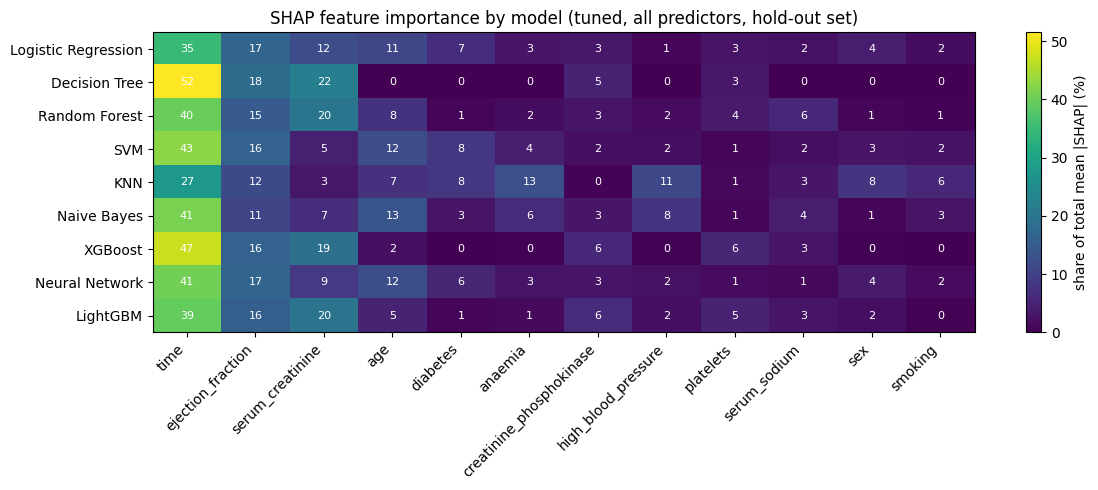

Saved: /kaggle/working/shap_importance_heatmap.png

Mean share of SHAP importance across models (%):
time                        40.5
ejection_fraction           15.3
serum_creatinine            12.9
age                          7.9
diabetes                     3.7
anaemia                      3.6
creatinine_phosphokinase     3.5
high_blood_pressure          3.1
platelets                    2.7
serum_sodium                 2.7
sex                          2.4
smoking                      1.7

Detailed SHAP plots for the best model by nested-CV AUC (tuned_all): Random Forest


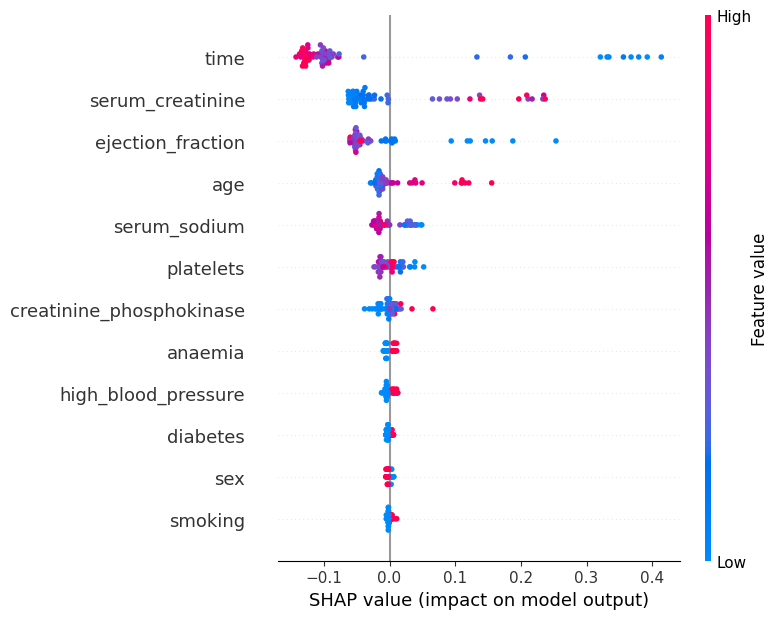

Saved: /kaggle/working/shap_summary_Random_Forest.png


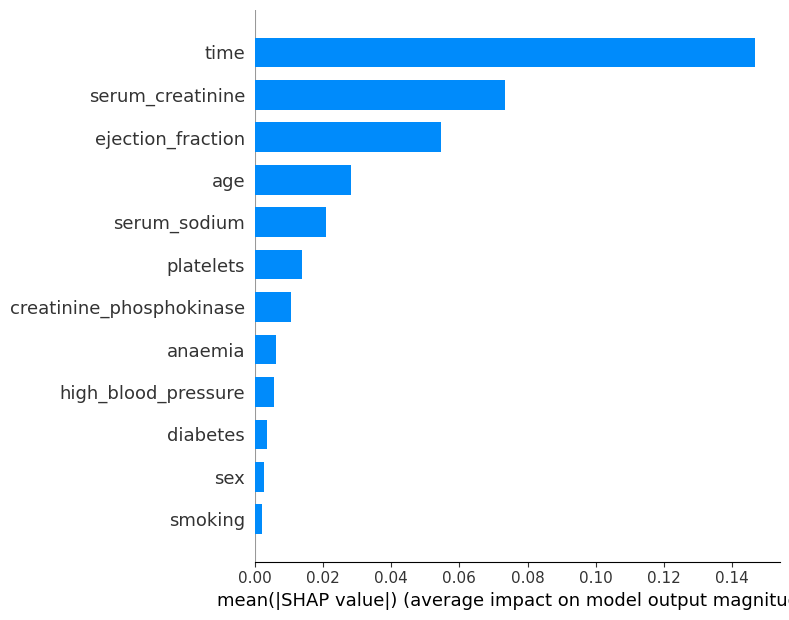

Saved: /kaggle/working/shap_bar_Random_Forest.png


<Figure size 640x480 with 0 Axes>

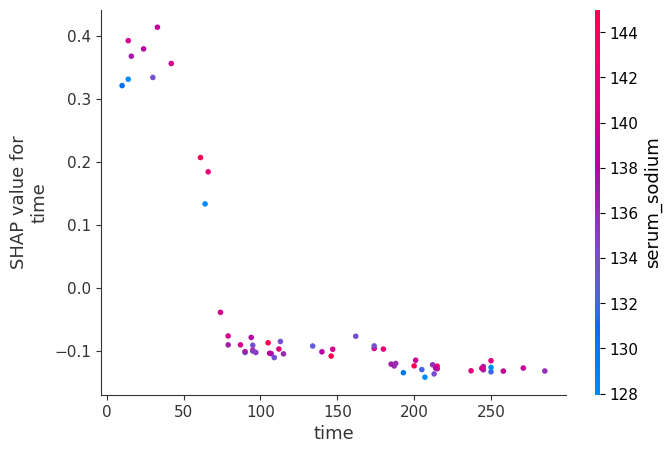

Saved: /kaggle/working/shap_dependence_Random_Forest_time.png

Top-4 by SHAP (Random Forest): ['time', 'serum_creatinine', 'ejection_fraction', 'age']
RankSumSelector top-4 (train split): ['time', 'serum_creatinine', 'ejection_fraction', 'age']
SHAP vs RankSum overlap: ['age', 'ejection_fraction', 'serum_creatinine', 'time']
Note: SHAP shows what the fitted model relies on; it is not a causal / clinical statement, and with 60 explained rows the ranking is noisy.


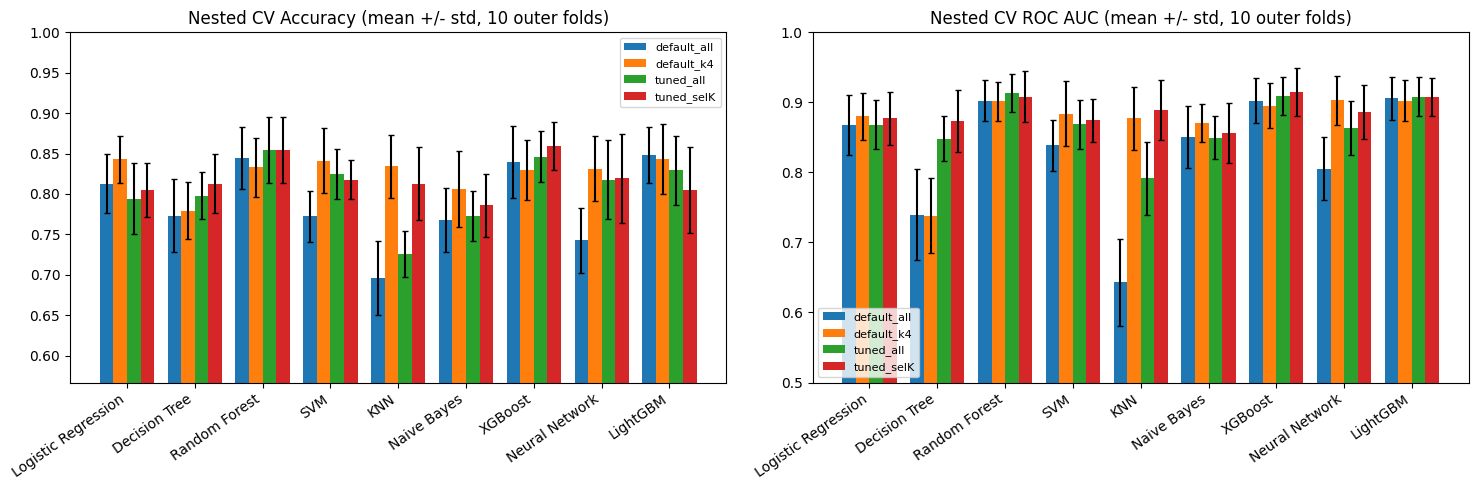

Saved: /kaggle/working/nestedcv_default_vs_tuned.png


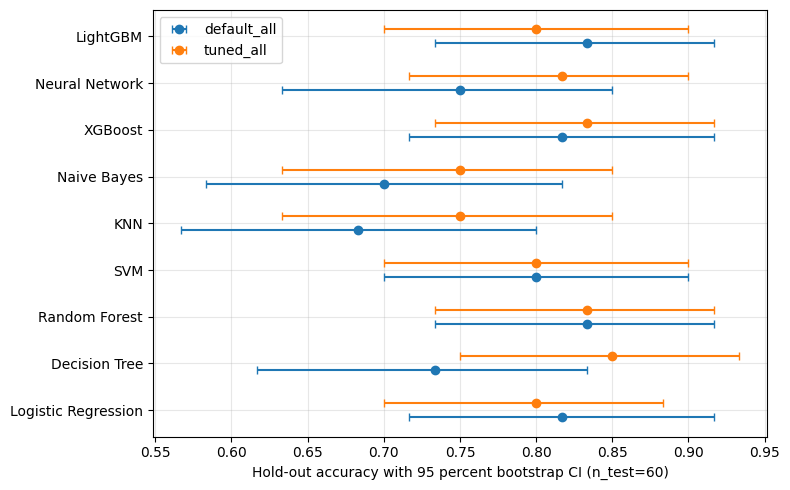

Saved: /kaggle/working/holdout_accuracy_ci.png

SUMMARY
Paired comparisons significant after Holm correction (alpha=0.05): 5
                                analysis   metric         model  mean_diff  p_holm
            Tuning effect (all features)  roc_auc Decision Tree     0.1081  0.0333
            Tuning effect (all features)  roc_auc           SVM     0.0305  0.0342
            Tuning effect (all features)  roc_auc           KNN     0.1484  0.0035
Selection effect (default settings, K=4) accuracy           KNN     0.1389  0.0404
Selection effect (default settings, K=4)  roc_auc           KNN     0.2342  0.0092

Highest nested-CV mean AUC: XGBoost / tuned_selK = 0.9150 +/- 0.0343. Check the Friedman / Nemenyi / Holm tables before calling any model 'best'.

Caveats: the hold-out test has only 60 rows; nested-CV folds overlap in training data so p-values are approximate and power is low (N=10 folds). Search spaces, K_GRID and SHAP settings are my own assumptions.

REFERENCE ONLY: the

In [1]:
# =============================================================================
# Faisalabad heart-failure - complete evaluation pipeline: baseline vs OPTIMISED models + STATISTICS + SHAP (XAI)
# (adapted from the original heart-disease evaluation pipeline for Faisalabad)
#
# WHAT THIS SCRIPT DOES
#  1. BASELINE: the same default models/pipelines/split as Part 1 (so numbers can be compared).
#  2. OPTIMISATION: hyper-parameter search per model on the TRAINING split only
#     (5-fold stratified inner CV, RandomizedSearchCV, scoring = ROC AUC). The test split is
#     never used for tuning. In the feature-selection variant the number of selected
#     features K is ALSO tuned inside the inner CV.
#  3. HOLD-OUT EVALUATION on the untouched 20% test split + bootstrap 95% CIs.
#  4. NESTED CROSS-VALIDATION on all de-duplicated rows (repeated stratified 5-fold outer loop,
#     tuning repeated inside every outer-training fold) = the main evidence; the 61-row test
#     split is not.
#  5. STATISTICS on the paired nested-CV fold scores: Nadeau-Bengio corrected paired t-test,
#     Friedman + Nemenyi critical difference, Holm-corrected Wilcoxon vs the best-ranked model,
#     paired bootstrap CIs on the hold-out set.
#  6. SHAP (explainable AI) for every tuned model (12 predictors) on the hold-out set, with detailed
#     plots for the best model (by nested-CV AUC) and a cross-model importance heat-map.
#
# OUTPUT: ONE main CSV  /kaggle/working/faisalabad_main_results.csv
#   The first column "record_type" says what each row is:
#     run_info          settings / data facts (item, value)
#     model_summary     one row per (model, variant): hold-out metrics, bootstrap CIs, nested-CV mean/std,
#                       best hyper-parameters, features used
#     nestedcv_fold     one row per (model, variant, outer fold)
#     stat_test         every statistical test (analysis, comparison, metric, p_value, p_holm, ...)
#     selector_rank     RankSumSelector rank-sum per feature (training split)
#     shap_importance   mean |SHAP| per (model, feature) on the hold-out set
#   (PNG figures are also saved in /kaggle/working/.)
#   The CSV is re-saved after every stage, so a crash late in the run cannot lose earlier results.
#
# HONESTY NOTES
#  - Tuning on ~240 rows often gives small or no gains; the script reports whatever it finds.
#  - Inner-CV best scores are optimistic by construction; only nested-CV / hold-out numbers
#    are reported as performance.
#  - Tests on 10 correlated CV folds have LOW POWER and approximate p-values.
#  - SHAP explains what the MODEL uses, not medical causality; its rankings are noisy on a small hold-out,
#    and SHAP scales differ between model types (so use the % columns to compare).
#  - No tuning on test data, no seed search (RANDOM_STATE = 42 throughout).
# =============================================================================

import os
os.environ["PYTHONWARNINGS"] = "ignore"        # also silences joblib worker processes

import glob
import time
import platform
import traceback
import warnings
from math import prod
from functools import partial

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
from scipy import stats
from scipy.stats import rankdata

import sklearn
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.feature_selection import SelectKBest, chi2, f_classif, mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     RepeatedStratifiedKFold, RandomizedSearchCV)
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier

warnings.filterwarnings("ignore")

# ----------------------------------------------------------------------------
# Configuration
# ----------------------------------------------------------------------------
RANDOM_STATE = 42
QUICK_MODE = False             # True = fast smoke test (fewer repeats / iterations)
K_FEATURES = 4                 # fixed-K baseline, used by the default_k4 variant
TEST_SIZE = 0.20
TUNE_SCORING = "roc_auc"       # smoother / less noisy than accuracy on ~240 rows
INNER_FOLDS = 5
OUTER_FOLDS = 5
OUTER_REPEATS = 2              # 5x2 = 10 paired outer folds
N_ITER = 20                    # random-search budget per model (capped at grid size)
N_BOOT = 1000                  # bootstrap resamples on the hold-out set
K_GRID = [3, 4, 5, 6, 8, 10]   # K values searched in the tuned_selK variant
N_JOBS = -1
ALPHA = 0.05                   # Nemenyi table below is for alpha = 0.05
RUN_SHAP = True
SHAP_BACKGROUND = 15           # background rows for KernelExplainer (SVM / KNN / NB / MLP)
SHAP_NSAMPLES = 300            # KernelExplainer samples per row (approximation, stated in CSV)

if QUICK_MODE:
    OUTER_REPEATS, N_ITER, N_BOOT, SHAP_NSAMPLES = 1, 8, 300, 100

DATA_PATH = "/kaggle/input/datasets/andrewmvd/heart-failure-clinical-data/heart_failure_clinical_records_dataset.csv"  # optionally set the full CSV path; blank = find a compatible Faisalabad CSV in INPUT_ROOT
INPUT_ROOT = "/kaggle/input"
OUT_DIR = "/kaggle/working"
MAIN_CSV = os.path.join(OUT_DIR, "faisalabad_main_results.csv")

FEATURES = ["age", "anaemia", "creatinine_phosphokinase", "diabetes",
            "ejection_fraction", "high_blood_pressure", "platelets",
            "serum_creatinine", "serum_sodium", "sex", "smoking", "time"]
TARGET_COLUMN = "death_event"
PAPER_RF_ACC_REFERENCE = 90.00  # paper reports approx. 90% before selection; Table 12 also reports 91.67% after selection
# Nemenyi q(0.05) from Demsar (2006), k = 2..10 classifiers
NEMENYI_Q05 = {2: 1.960, 3: 2.343, 4: 2.569, 5: 2.728, 6: 2.850, 7: 2.949, 8: 3.031, 9: 3.102, 10: 3.164}

os.makedirs(OUT_DIR, exist_ok=True)
np.random.seed(RANDOM_STATE)
T0 = time.time()


def safe_run(label, fn):
    """Run a stage; if it fails, print the traceback and CONTINUE (earlier results are kept)."""
    try:
        return fn()
    except Exception as e:  # noqa
        print(f"\n!!! STAGE FAILED: {label}: {type(e).__name__}: {e}")
        traceback.print_exc()
        return None


print("=" * 78)
print("LIBRARY VERSIONS / SETTINGS")
print("=" * 78)
print("python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scipy", scipy.__version__, "| sklearn", sklearn.__version__)
print("cpu cores:", os.cpu_count(), "| QUICK_MODE:", QUICK_MODE)
XGBClassifier, XGB_SKIP = None, None
try:
    import xgboost
    from xgboost import XGBClassifier
    print("xgboost", xgboost.__version__)
except Exception as e:  # noqa
    XGB_SKIP = f"xgboost import failed: {type(e).__name__}: {e}"
    print("xgboost NOT AVAILABLE ->", XGB_SKIP)
LGBMClassifier, LGBM_SKIP = None, None
try:
    import lightgbm
    from lightgbm import LGBMClassifier
    print("lightgbm", lightgbm.__version__)
except Exception as e:  # noqa
    LGBM_SKIP = f"lightgbm import failed: {type(e).__name__}: {e}"
    print("lightgbm NOT AVAILABLE ->", LGBM_SKIP)
shap = None
SHAP_SKIP = None
if RUN_SHAP:
    try:
        import shap
        print("shap", shap.__version__)
    except Exception as e:  # noqa
        SHAP_SKIP = f"shap import failed: {type(e).__name__}: {e}"
        print("shap NOT AVAILABLE ->", SHAP_SKIP, "(SHAP stage will be skipped)")

# ============================================================================
# DATA (Faisalabad loading, cleaning, and stratified split)
# ============================================================================
print("\n" + "=" * 78)
print("DATA")
print("=" * 78)


def normalize_column_name(name):
    """Normalize common CSV header differences while preserving the dataset fields."""
    return str(name).strip().lower().replace(" ", "_").replace("-", "_")


def find_csv(root=INPUT_ROOT, explicit=DATA_PATH):
    """Find a CSV with all Faisalabad predictor fields and the DEATH_EVENT label."""
    if explicit and os.path.isfile(explicit):
        return explicit
    if explicit:
        print(f"DATA_PATH not found ({explicit}); searching for a compatible CSV.")
    if os.path.isfile(root):
        cands = [root]
    else:
        cands = sorted(glob.glob(os.path.join(root, "**", "*.csv"), recursive=True))
        if not cands and root != "/kaggle/input":
            cands = sorted(glob.glob("/kaggle/input/**/*.csv", recursive=True))
    if not cands:
        raise FileNotFoundError("No CSV found. Add the Faisalabad heart-failure CSV under /kaggle/input or set DATA_PATH.")
    required = set(FEATURES + [TARGET_COLUMN])
    valid = []
    for path in cands:
        try:
            cols = {normalize_column_name(c) for c in pd.read_csv(path, nrows=0).columns}
        except Exception:
            continue
        if required <= cols:
            valid.append(path)
    if not valid:
        raise FileNotFoundError(
            "No CSV has the Faisalabad schema. Required columns: " + ", ".join(FEATURES + [TARGET_COLUMN])
        )
    preferred = [p for p in valid if "heart_failure_clinical_records_dataset" in os.path.basename(p).lower()]
    return (preferred or valid)[0]


data_path = find_csv()
print("USING CSV:", data_path)
raw = pd.read_csv(data_path, na_values=["?", "NA", "N/A", "", " "])
raw.columns = [normalize_column_name(c) for c in raw.columns]
required = FEATURES + [TARGET_COLUMN]
missing_columns = [c for c in required if c not in raw.columns]
if missing_columns:
    raise ValueError(f"Missing required Faisalabad columns: {missing_columns}")

df = raw[required].apply(pd.to_numeric, errors="coerce").copy()
# Drop only rows whose outcome is missing/invalid; predictors are imputed within each training fold.
invalid_target = df[TARGET_COLUMN].isna() | ~df[TARGET_COLUMN].isin([0, 1])
if invalid_target.any():
    print(f"Dropping {int(invalid_target.sum())} rows with missing/non-binary {TARGET_COLUMN}.")
    df = df.loc[~invalid_target].copy()
df[TARGET_COLUMN] = df[TARGET_COLUMN].astype(int)

n_loaded = len(raw)
n_exact_duplicates = int(df.duplicated().sum())
# Keep repeated rows: they may represent distinct patients, and the source provides no patient IDs
# with which to determine whether repeated feature/label rows are duplicate records.
df = df.reset_index(drop=True)
print(f"Rows loaded {n_loaded} -> analysis rows {len(df)}; exact repeated rows retained: {n_exact_duplicates}")
print("Missing predictor values (total):", int(df[FEATURES].isna().sum().sum()))
print("Class balance (DEATH_EVENT):", df[TARGET_COLUMN].value_counts().sort_index().to_dict(),
      "| positive class 1 = death event")
if df[TARGET_COLUMN].nunique() != 2:
    raise ValueError("DEATH_EVENT must contain both binary classes 0 and 1 after cleaning.")
if int(df[TARGET_COLUMN].value_counts().min()) < max(INNER_FOLDS, OUTER_FOLDS):
    raise ValueError("Each target class needs at least as many rows as the CV fold count.")

X, y = df[FEATURES], df[TARGET_COLUMN]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)
print(f"Train {len(X_train)} | Test {len(X_test)} (stratified {100 * (1 - TEST_SIZE):.0f}/{100 * TEST_SIZE:.0f} split)")
y_test_np = y_test.values

# ============================================================================
# Feature selector (training-fold RankSumSelector: rank-sum of chi2 / F / MI, train-only)
# ============================================================================


class RankSumSelector(BaseEstimator, TransformerMixin):
    """Top-k features by summed ranks of chi2, f_classif and mutual_info_classif (1 = best)."""

    def __init__(self, k=4, feature_names=None, random_state=42):
        self.k = k
        self.feature_names = feature_names
        self.random_state = random_state

    def fit(self, X, y):
        Xa = np.asarray(X, dtype=float)
        n = Xa.shape[1]
        names = list(self.feature_names) if self.feature_names is not None else [f"x{i}" for i in range(n)]
        k = min(int(self.k), n)
        fns = {"chi2": chi2, "f": f_classif,
               "mi": partial(mutual_info_classif, random_state=self.random_state)}
        rank_sum = np.zeros(n)
        for fn in fns.values():
            s = np.nan_to_num(np.asarray(SelectKBest(fn, k="all").fit(Xa, y).scores_, float), nan=0.0)
            rank_sum += rankdata(-s, method="average")
        order = np.argsort(rank_sum, kind="stable")
        self.selected_idx_ = order[:k]
        self.selected_features_ = [names[i] for i in self.selected_idx_]
        self.rank_sum_ = dict(zip(names, rank_sum.tolist()))
        self.n_features_in_ = n
        return self

    def transform(self, X):
        return np.asarray(X, dtype=float)[:, self.selected_idx_]


def build_pipeline(model, use_selection):
    steps = [("imputer", SimpleImputer(strategy="median")), ("scaler", MinMaxScaler())]
    if use_selection:
        steps.append(("selector", RankSumSelector(k=K_FEATURES, feature_names=FEATURES,
                                                  random_state=RANDOM_STATE)))
    steps.append(("model", model))
    return Pipeline(steps)


# Reference selection on the training split (for printing / CSV / comparison with SHAP)
ref_sel = build_pipeline(LogisticRegression(max_iter=1000), True).fit(X_train, y_train).named_steps["selector"]
print(f"\nRankSumSelector (K={K_FEATURES}, train split) selected: {ref_sel.selected_features_}")
print("Selected features are ranked from the training split only.")

# ============================================================================
# Models: default factory (identical to Part 1) + search spaces
# ============================================================================


def make_model(name, search=False):
    """search=True only pins tree libraries to 1 thread to avoid CPU over-subscription
    while the search itself runs in parallel. Hyper-parameter defaults are unchanged."""
    rs = RANDOM_STATE
    if name == "Logistic Regression":
        return LogisticRegression(max_iter=1000, random_state=rs)
    if name == "Decision Tree":
        return DecisionTreeClassifier(criterion="entropy", random_state=rs)
    if name == "Random Forest":
        return RandomForestClassifier(n_estimators=100, random_state=rs, n_jobs=1 if search else None)
    if name == "SVM":
        return SVC(kernel="rbf", probability=True, random_state=rs)
    if name == "KNN":
        return KNeighborsClassifier(n_neighbors=5)
    if name == "Naive Bayes":
        return GaussianNB()
    if name == "XGBoost":
        return XGBClassifier(random_state=rs, eval_metric="logloss", n_jobs=1 if search else None)
    if name == "Neural Network":
        return MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=1000, random_state=rs)
    if name == "LightGBM":
        kw = dict(n_jobs=1, subsample_freq=1) if search else {}
        return LGBMClassifier(random_state=rs, verbose=-1, **kw)
    raise KeyError(name)


# Search spaces (my own choices - not from the paper; all are ASSUMPTIONS)
GRIDS = {
    "Logistic Regression": {"C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30, 100],
                            "class_weight": [None, "balanced"]},
    "Decision Tree": {"criterion": ["entropy", "gini"], "max_depth": [2, 3, 4, 5, 6, 8, None],
                      "min_samples_leaf": [1, 2, 5, 10], "min_samples_split": [2, 5, 10],
                      "ccp_alpha": [0.0, 0.005, 0.01, 0.02, 0.04]},
    "Random Forest": {"n_estimators": [100, 200, 300, 500], "max_depth": [None, 3, 5, 8],
                      "min_samples_leaf": [1, 2, 4], "max_features": ["sqrt", "log2", 0.5]},
    "SVM": {"C": [0.1, 0.3, 1, 3, 10, 30, 100], "gamma": ["scale", 0.003, 0.01, 0.03, 0.1, 0.3, 1]},
    "KNN": {"n_neighbors": [3, 5, 7, 9, 11, 15, 21], "weights": ["uniform", "distance"], "p": [1, 2]},
    "Naive Bayes": {"var_smoothing": list(np.logspace(-9, -1, 9))},
    "XGBoost": {"n_estimators": [50, 100, 200, 300], "max_depth": [2, 3, 4, 6],
                "learning_rate": [0.01, 0.03, 0.1, 0.3], "subsample": [0.7, 0.85, 1.0],
                "colsample_bytree": [0.7, 0.85, 1.0], "min_child_weight": [1, 3, 5],
                "reg_lambda": [1, 5, 10]},
    "Neural Network": {"hidden_layer_sizes": [(32,), (64,), (64, 32), (128, 64)],
                       "alpha": [1e-4, 1e-3, 1e-2, 1e-1], "learning_rate_init": [1e-3, 3e-3, 1e-2]},
    "LightGBM": {"n_estimators": [50, 100, 200, 300], "num_leaves": [4, 8, 15, 31],
                 "learning_rate": [0.01, 0.03, 0.1, 0.3], "min_child_samples": [5, 10, 20],
                 "subsample": [0.7, 0.85, 1.0], "colsample_bytree": [0.7, 1.0],
                 "reg_lambda": [0, 1, 5]},
}
SKIP = {"XGBoost": XGB_SKIP, "LightGBM": LGBM_SKIP}
MODEL_NAMES = [m for m in GRIDS if SKIP.get(m) is None]
for _m, _why in SKIP.items():
    if _why:
        print(f"[skip] {_m}: {_why}")

VARIANTS = {                                   # name -> (use_selection, tune)
    "default_all": (False, False),             # baseline, 12 predictors, default settings
    "default_k4": (True, False),               # baseline, fixed K=4 selection
    "tuned_all": (False, True),                # 12 predictors, tuned
    "tuned_selK": (True, True),                # selection with K tuned + model tuned
}
INNER_CV = StratifiedKFold(n_splits=INNER_FOLDS, shuffle=True, random_state=RANDOM_STATE)


def make_estimator(name, variant):
    use_sel, tune = VARIANTS[variant]
    pipe = build_pipeline(make_model(name, search=tune), use_sel)
    if not tune:
        return pipe
    grid = {f"model__{k}": v for k, v in GRIDS[name].items()}
    if use_sel:
        grid["selector__k"] = K_GRID
    size = prod(len(v) for v in grid.values())
    n_iter = min(int(N_ITER * (1.5 if use_sel else 1.0)), size)
    return RandomizedSearchCV(pipe, grid, n_iter=n_iter, scoring=TUNE_SCORING, cv=INNER_CV,
                              n_jobs=N_JOBS, random_state=RANDOM_STATE, refit=True,
                              error_score="raise")


def fitted_pipe(est):
    return est.best_estimator_ if hasattr(est, "best_estimator_") else est


def clean_params(p):
    out = {}
    for k, v in p.items():
        k2 = k.replace("model__", "").replace("selector__", "sel_")
        out[k2] = float(v) if isinstance(v, np.floating) else (int(v) if isinstance(v, np.integer) else v)
    return out


# ----------------------------------------------------------------------------
# Global result containers + the ONE main CSV writer
# ----------------------------------------------------------------------------
hold = pd.DataFrame()          # model_summary rows
folds = pd.DataFrame()         # nestedcv_fold rows
stat_rows = []                 # stat_test rows
shap_rows = []                 # shap_importance rows
hold_pred, hold_fit, boot = {}, {}, {}

RUN_INFO = {
    "data_path": data_path, "rows_loaded": n_loaded, "rows_after_cleaning": len(df), "exact_repeated_rows_retained": n_exact_duplicates,
    "train_size": len(X_train), "test_size": len(X_test), "random_state": RANDOM_STATE,
    "positive_class": "1 (DEATH_EVENT: event occurred)", "tune_scoring": TUNE_SCORING,
    "search": f"RandomizedSearchCV n_iter<={N_ITER} (x1.5 for tuned_selK), inner {INNER_FOLDS}-fold",
    "nested_cv": f"outer {OUTER_FOLDS}-fold x {OUTER_REPEATS} repeats", "n_boot": N_BOOT,
    "k_grid": str(K_GRID), "k_default_variant": K_FEATURES, "quick_mode": QUICK_MODE,
    "sklearn": sklearn.__version__, "shap": (shap.__version__ if shap is not None else f"unavailable ({SHAP_SKIP})"),
    "xgboost": "available" if XGBClassifier is not None else f"SKIPPED ({XGB_SKIP})",
    "lightgbm": "available" if LGBMClassifier is not None else f"SKIPPED ({LGBM_SKIP})",
}

MAIN_COLUMNS = [
    "record_type", "model", "variant", "fold", "analysis", "comparison", "metric", "feature", "item", "value",
    "n_features", "features_used", "best_params", "inner_cv_best_auc",
    "accuracy", "precision", "recall", "f1", "specificity", "classification_error", "roc_auc",
    "tn", "fp", "fn", "tp", "acc_ci_low", "acc_ci_high", "auc_ci_low", "auc_ci_high",
    "cv_accuracy_mean", "cv_accuracy_std", "cv_f1_mean", "cv_f1_std", "cv_auc_mean", "cv_auc_std", "n_folds",
    "fold_accuracy", "fold_f1", "fold_auc",
    "mean_diff", "diff_ci_low", "diff_ci_high", "statistic", "p_value", "p_holm", "test_name",
    "rank_sum", "selected_by_ranksum", "mean_abs_shap", "mean_abs_shap_pct", "shap_rank", "shap_method",
    "train_size", "test_size", "random_state", "notes"]


def save_main_csv():
    parts = [pd.DataFrame([dict(record_type="run_info", item=k, value=str(v)) for k, v in RUN_INFO.items()])]
    if len(hold):
        parts.append(hold.assign(record_type="model_summary"))
    if len(folds):
        parts.append(folds.rename(columns={"accuracy": "fold_accuracy", "f1": "fold_f1", "roc_auc": "fold_auc"})
                     .assign(record_type="nestedcv_fold"))
    if stat_rows:
        parts.append(pd.DataFrame(stat_rows).rename(columns={"ci_low": "diff_ci_low", "ci_high": "diff_ci_high",
                                                             "t": "statistic", "p": "p_value", "test": "test_name"})
                     .assign(record_type="stat_test"))
    parts.append(pd.DataFrame(
        [dict(record_type="selector_rank", feature=f, rank_sum=v, selected_by_ranksum=(f in ref_sel.selected_features_),
              notes=f"RankSumSelector fitted on training split; lower rank_sum = better; K={K_FEATURES}")
         for f, v in sorted(ref_sel.rank_sum_.items(), key=lambda kv: kv[1])]))
    if shap_rows:
        parts.append(pd.DataFrame(shap_rows).assign(record_type="shap_importance"))
    out = pd.concat([p for p in parts if len(p)], ignore_index=True, sort=False)
    for c in MAIN_COLUMNS:
        if c not in out.columns:
            out[c] = np.nan
    extra = [c for c in out.columns if c not in MAIN_COLUMNS]
    out = out[MAIN_COLUMNS + extra]
    out.to_csv(MAIN_CSV, index=False)
    print(f"   [main CSV saved: {len(out)} rows -> {MAIN_CSV}]")


# ============================================================================
# PHASE 1+2 - HOLD-OUT: baseline vs tuned (tuning on training split only)
# ============================================================================
print("\n" + "=" * 78)
print("PHASE 1+2 - HOLD-OUT EVALUATION: DEFAULT vs TUNED (tuned on the TRAINING split only)")
print("=" * 78)

holdout_rows = []
for name in MODEL_NAMES:
    for variant, (use_sel, tune) in VARIANTS.items():
        row = dict(model=name, variant=variant, n_features=np.nan, features_used="",
                   best_params="", inner_cv_best_auc=np.nan, notes="")
        try:
            est = make_estimator(name, variant)
            est.fit(X_train, y_train)
            fp = fitted_pipe(est)
            if tune:
                row["best_params"] = str(clean_params(est.best_params_))
                row["inner_cv_best_auc"] = est.best_score_
                row["notes"] = (f"tuned on train only: RandomizedSearchCV n_iter={est.n_iter}, "
                                f"{INNER_FOLDS}-fold CV, scoring={TUNE_SCORING}")
            feats = list(fp.named_steps["selector"].selected_features_) if use_sel else list(FEATURES)
            pred = fp.predict(X_test)
            proba = fp.predict_proba(X_test)[:, 1]
            tn, fpos, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
            acc = accuracy_score(y_test, pred)
            row.update(n_features=len(feats), features_used=";".join(feats), accuracy=acc,
                       precision=precision_score(y_test, pred, zero_division=0),
                       recall=recall_score(y_test, pred, zero_division=0),
                       f1=f1_score(y_test, pred, zero_division=0),
                       specificity=tn / (tn + fpos) if (tn + fpos) else np.nan,
                       classification_error=1 - acc, roc_auc=roc_auc_score(y_test, proba),
                       tn=int(tn), fp=int(fpos), fn=int(fn), tp=int(tp))
            hold_pred[(name, variant)] = (pred, proba)
            hold_fit[(name, variant)] = fp
        except Exception as e:  # noqa
            row["notes"] += f" | HOLD-OUT ERROR: {type(e).__name__}: {e}"
        holdout_rows.append(row)
        extra = f" best={row['best_params']}" if tune and row["best_params"] else ""
        print(f"[{time.time() - T0:6.0f}s] {name:20s} {variant:12s} test_acc={row.get('accuracy', np.nan):.4f} "
              f"auc={row.get('roc_auc', np.nan):.4f}{extra}")
for _m, _why in SKIP.items():
    if _why:
        holdout_rows.append(dict(model=_m, variant="all", notes=f"SKIPPED: {_why}"))
hold = pd.DataFrame(holdout_rows)

# ---- bootstrap CIs on the hold-out set (same resample indices for every variant -> paired) ----
rng = np.random.default_rng(RANDOM_STATE)
BIDX = rng.integers(0, len(y_test_np), size=(N_BOOT, len(y_test_np)))
YB = y_test_np[BIDX]
valid_b = YB.min(axis=1) != YB.max(axis=1)


def boot_arrays(pred, proba):
    acc = (pred[BIDX] == YB).mean(axis=1)
    auc = np.full(N_BOOT, np.nan)
    for b in np.where(valid_b)[0]:
        auc[b] = roc_auc_score(YB[b], proba[BIDX[b]])
    return acc, auc


def add_bootstrap():
    global hold
    for k, v in hold_pred.items():
        boot[k] = boot_arrays(*v)
    for metric, pos in (("acc", 0), ("auc", 1)):
        lo, hi = [], []
        for _, r in hold.iterrows():
            key = (r["model"], r["variant"])
            if key in boot:
                lo_, hi_ = np.nanpercentile(boot[key][pos], [2.5, 97.5])
            else:
                lo_, hi_ = np.nan, np.nan
            lo.append(lo_)
            hi.append(hi_)
        hold[f"{metric}_ci_low"], hold[f"{metric}_ci_high"] = lo, hi


safe_run("bootstrap CIs", add_bootstrap)
hold["train_size"], hold["test_size"], hold["random_state"] = len(X_train), len(X_test), RANDOM_STATE
save_main_csv()

# ============================================================================
# PHASE 3 - NESTED CROSS-VALIDATION (main evidence)
# ============================================================================
print("\n" + "=" * 78)
print(f"PHASE 3 - NESTED CV on all {len(df)} rows: outer {OUTER_FOLDS}-fold x {OUTER_REPEATS} repeats, "
      f"inner {INNER_FOLDS}-fold tuning inside every outer-training fold")
print("=" * 78)
outer = RepeatedStratifiedKFold(n_splits=OUTER_FOLDS, n_repeats=OUTER_REPEATS, random_state=RANDOM_STATE)
SPLITS = list(outer.split(X, y))
N_FOLDS = len(SPLITS)
fold_rows = []
for name in MODEL_NAMES:
    for variant, (use_sel, tune) in VARIANTS.items():
        try:
            for fi, (tr, te) in enumerate(SPLITS):
                est = make_estimator(name, variant)
                est.fit(X.iloc[tr], y.iloc[tr])
                fp = fitted_pipe(est)
                pred = fp.predict(X.iloc[te])
                proba = fp.predict_proba(X.iloc[te])[:, 1]
                fold_rows.append(dict(
                    model=name, variant=variant, fold=fi,
                    accuracy=accuracy_score(y.iloc[te], pred), f1=f1_score(y.iloc[te], pred, zero_division=0),
                    roc_auc=roc_auc_score(y.iloc[te], proba),
                    best_params=str(clean_params(est.best_params_)) if tune else ""))
        except Exception as e:  # noqa
            print(f"   !! {name}/{variant} failed: {type(e).__name__}: {e}")
    print(f"[{time.time() - T0:6.0f}s] nested CV done for {name}")

folds = pd.DataFrame(fold_rows)
summ = folds.groupby(["model", "variant"]).agg(
    cv_accuracy_mean=("accuracy", "mean"), cv_accuracy_std=("accuracy", "std"),
    cv_f1_mean=("f1", "mean"), cv_f1_std=("f1", "std"),
    cv_auc_mean=("roc_auc", "mean"), cv_auc_std=("roc_auc", "std"),
    n_folds=("fold", "count")).reset_index()
hold = hold.merge(summ, on=["model", "variant"], how="left")
save_main_csv()

# ============================================================================
# RESULTS TABLES
# ============================================================================
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", None)
ho = hold[hold["variant"].isin(list(VARIANTS))]


def print_results():
    print("\n" + "=" * 78)
    print(f"RESULT 1 - HOLD-OUT test accuracy / AUC (n_test = {len(X_test)}; "
          f"1 prediction = {100 / len(X_test):.2f} pts)")
    print("=" * 78)
    tab = ho.pivot(index="model", columns="variant", values="accuracy")[list(VARIANTS)].round(4)
    tab_auc = ho.pivot(index="model", columns="variant", values="roc_auc")[list(VARIANTS)].round(4)
    print("Accuracy:\n", tab.to_string())
    print("\nROC AUC:\n", tab_auc.to_string())

    print("\n" + "=" * 78)
    print(f"RESULT 2 - NESTED CV (mean +/- std over {N_FOLDS} outer folds) - the more reliable numbers")
    print("=" * 78)
    for metric, label in (("accuracy", "Accuracy"), ("roc_auc", "ROC AUC")):
        mm = folds.pivot_table(index="model", columns="variant", values=metric, aggfunc="mean")[list(VARIANTS)]
        ss = folds.pivot_table(index="model", columns="variant", values=metric, aggfunc="std")[list(VARIANTS)]
        out = mm.round(4).astype(str) + " +/-" + ss.round(3).astype(str)
        print(f"\n{label}:\n", out.to_string())

    print("\n" + "=" * 78)
    print("RESULT 3 - HOLD-OUT 95% bootstrap CIs (default_all and tuned_all)")
    print("=" * 78)
    ci = ho[ho["variant"].isin(["default_all", "tuned_all"])][
        ["model", "variant", "accuracy", "acc_ci_low", "acc_ci_high", "roc_auc", "auc_ci_low", "auc_ci_high"]]
    print(ci.round(3).to_string(index=False))


safe_run("results tables", print_results)

# ============================================================================
# STATISTICAL ANALYSIS
# ============================================================================


def holm(p):
    p = np.nan_to_num(np.asarray(p, float), nan=1.0)
    order = np.argsort(p)
    adj = np.empty(len(p))
    run = 0.0
    for r, i in enumerate(order):
        run = max(run, (len(p) - r) * p[i])
        adj[i] = min(1.0, run)
    return adj


def scores(model, variant, metric):
    d = folds[(folds.model == model) & (folds.variant == variant)].sort_values("fold")
    return d[metric].values


def corrected_ttest(d, test_frac):
    """Nadeau & Bengio (2003) corrected resampled paired t-test. test_frac = n_test / n_train."""
    d = np.asarray(d, float)
    J = len(d)
    var = d.var(ddof=1)
    se = np.sqrt((1.0 / J + test_frac) * var)
    if se == 0 or not np.isfinite(se):
        return d.mean(), np.nan, (1.0 if d.mean() == 0 else np.nan), d.mean(), d.mean()
    t = d.mean() / se
    p = 2 * stats.t.sf(abs(t), J - 1)
    h = stats.t.ppf(0.975, J - 1) * se
    return d.mean(), t, p, d.mean() - h, d.mean() + h


def run_statistics():
    print("\n" + "=" * 78)
    print("STATISTICAL ANALYSIS (paired over the same nested-CV outer folds)")
    print("=" * 78)
    test_frac = 1.0 / (OUTER_FOLDS - 1)

    # ---- A/B: paired comparisons per model ----------------------------------------------------
    families = [("Tuning effect (all features)", "tuned_all", "default_all"),
                ("Tuning effect (selected features)", "tuned_selK", "default_k4"),
                ("Selection effect (default settings, K=4)", "default_k4", "default_all"),
                ("Selection effect (tuned, K tuned)", "tuned_selK", "tuned_all")]
    for fam, a, b in families:
        for metric in ("accuracy", "roc_auc"):
            recs = []
            for m in MODEL_NAMES:
                sa, sb = scores(m, a, metric), scores(m, b, metric)
                if len(sa) != N_FOLDS or len(sb) != N_FOLDS:
                    continue
                md, t, p, lo, hi = corrected_ttest(sa - sb, test_frac)
                recs.append(dict(analysis=fam, comparison=f"{a} - {b}", metric=metric, model=m,
                                 mean_diff=md, ci_low=lo, ci_high=hi, t=t, p=p))
            if recs:
                adj = holm([r["p"] for r in recs])
                for r, pa in zip(recs, adj):
                    r["p_holm"] = pa
                    r["test"] = "Nadeau-Bengio corrected paired t-test"
                stat_rows.extend(recs)
                print(f"\n{fam} | {a} - {b} | metric = {metric} (positive = first is better)")
                print(pd.DataFrame(recs)[["model", "mean_diff", "ci_low", "ci_high", "p", "p_holm"]]
                      .round(4).to_string(index=False))
    save_main_csv()

    # ---- C: Friedman + Nemenyi + Holm-Wilcoxon across models -----------------------------------
    for variant in ("default_all", "tuned_all"):
        for metric in ("accuracy", "roc_auc"):
            mats = {m: scores(m, variant, metric) for m in MODEL_NAMES if len(scores(m, variant, metric)) == N_FOLDS}
            k = len(mats)
            if k < 3:
                continue
            M = np.column_stack(list(mats.values()))                  # folds x models
            names = list(mats.keys())
            try:
                chi, pf = stats.friedmanchisquare(*[M[:, j] for j in range(k)])
            except Exception:
                chi, pf = np.nan, np.nan
            ranks = np.apply_along_axis(lambda r: rankdata(-r), 1, M)   # rank 1 = best in each fold
            avg = ranks.mean(axis=0)
            q = NEMENYI_Q05.get(k)
            cd = q * np.sqrt(k * (k + 1) / (6.0 * N_FOLDS)) if q is not None else np.nan
            order = np.argsort(avg)
            best = names[order[0]]
            cd_txt = f"{cd:.2f} rank units" if np.isfinite(cd) else "n/a"
            print(f"\n--- Across-model comparison | variant = {variant} | metric = {metric} ---")
            print(f"Friedman chi2 = {chi:.3f}, p = {pf:.4f} (k={k} models, N={N_FOLDS} folds). "
                  f"Nemenyi critical difference (alpha=0.05) = {cd_txt}.")
            recs = []
            for j in order[1:]:
                try:
                    pw = float(stats.wilcoxon(M[:, order[0]], M[:, j]).pvalue)
                except Exception:
                    pw = 1.0
                recs.append(dict(model=names[j], avg_rank=avg[j], rank_gap=avg[j] - avg[order[0]],
                                 mean_diff_vs_best=float((M[:, order[0]] - M[:, j]).mean()), p_wilcoxon=pw))
            adj = holm([r["p_wilcoxon"] for r in recs])
            tbl = [dict(model=best, avg_rank=avg[order[0]], rank_gap=0.0, mean_diff_vs_best=0.0,
                        p_wilcoxon=np.nan, p_holm=np.nan, note="best average rank")]
            for r, pa in zip(recs, adj):
                note = "n/a" if not np.isfinite(cd) else ("within Nemenyi CD" if r["rank_gap"] < cd else "beyond CD")
                tbl.append(dict(model=r["model"], avg_rank=r["avg_rank"], rank_gap=r["rank_gap"],
                                mean_diff_vs_best=r["mean_diff_vs_best"], p_wilcoxon=r["p_wilcoxon"],
                                p_holm=pa, note=note))
            tdf = pd.DataFrame(tbl)
            print(tdf.round(4).to_string(index=False))
            stat_rows.append(dict(analysis="Friedman across models", comparison=variant, metric=metric,
                                  model="ALL", t=chi, p=pf,
                                  test=f"Friedman; Nemenyi CD={cd:.3f}; best average rank={best}"))
            for _, r in tdf.iterrows():
                if r["note"] != "best average rank":
                    stat_rows.append(dict(analysis="Best-ranked vs others (Holm-Wilcoxon)",
                                          comparison=f"{best} vs {r['model']} [{variant}]", metric=metric,
                                          model=r["model"], mean_diff=r["mean_diff_vs_best"], p=r["p_wilcoxon"],
                                          p_holm=r["p_holm"], test="Wilcoxon signed-rank, Holm-adjusted"))
    save_main_csv()

    # ---- D: paired bootstrap on hold-out (tuned_all - default_all) ------------------------------
    print(f"\n--- Hold-out paired bootstrap: tuned_all - default_all (95 percent CI; n_test={len(X_test)}) ---")
    brecs = []
    for m in MODEL_NAMES:
        if (m, "tuned_all") in boot and (m, "default_all") in boot:
            for pos, metric in ((0, "accuracy"), (1, "roc_auc")):
                d = boot[(m, "tuned_all")][pos] - boot[(m, "default_all")][pos]
                lo, hi = np.nanpercentile(d, [2.5, 97.5])
                brecs.append(dict(model=m, metric=metric, mean_diff=np.nanmean(d), ci_low=lo, ci_high=hi,
                                  ci_excludes_0=bool(lo > 0 or hi < 0)))
                stat_rows.append(dict(analysis="Hold-out paired bootstrap", comparison="tuned_all - default_all",
                                      metric=metric, model=m, mean_diff=np.nanmean(d), ci_low=lo, ci_high=hi,
                                      test="percentile bootstrap"))
    if brecs:
        print(pd.DataFrame(brecs).round(4).to_string(index=False))
    save_main_csv()


safe_run("statistical analysis", run_statistics)

# ============================================================================
# SHAP (XAI) - tuned_all pipelines (all Faisalabad predictors), explained on the hold-out set
# ============================================================================
SHAP_STORE = {}          # model -> SHAP matrix (n_test x n_features), positive class (DEATH_EVENT=1)


def to_pos_class(sv):
    """Normalise SHAP output of different explainers / versions to (n_samples, n_features), class 1."""
    if isinstance(sv, list):
        sv = sv[1] if len(sv) > 1 else sv[0]
    sv = np.asarray(sv)
    if sv.ndim == 3:
        sv = sv[:, :, 1] if sv.shape[2] > 1 else sv[:, :, 0]
    return sv


def kernel_shap(mdl, Xtr_t, Xte_t):
    rs = np.random.RandomState(RANDOM_STATE)
    bg = Xtr_t[rs.choice(len(Xtr_t), size=min(SHAP_BACKGROUND, len(Xtr_t)), replace=False)]
    ex = shap.KernelExplainer(lambda d: mdl.predict_proba(d)[:, 1], bg)
    np.random.seed(RANDOM_STATE)
    try:
        sv = ex.shap_values(Xte_t, nsamples=SHAP_NSAMPLES, silent=True)
    except TypeError:
        sv = ex.shap_values(Xte_t, nsamples=SHAP_NSAMPLES)
    return to_pos_class(sv), f"KernelExplainer(bg={len(bg)}, nsamples={SHAP_NSAMPLES}; probability scale)"


def shap_for_model(name, mdl, Xtr_t, Xte_t):
    """Fast exact explainer when possible, KernelExplainer as a fallback."""
    try:
        if name == "Logistic Regression":
            sv = shap.LinearExplainer(mdl, Xtr_t).shap_values(Xte_t)
            return to_pos_class(sv), "LinearExplainer (log-odds scale)"
        if name in ("Random Forest", "Decision Tree"):
            sv = shap.TreeExplainer(mdl).shap_values(Xte_t, check_additivity=False)
            return to_pos_class(sv), "TreeExplainer (probability scale)"
        if name in ("XGBoost", "LightGBM"):
            sv = shap.TreeExplainer(mdl).shap_values(Xte_t)
            return to_pos_class(sv), "TreeExplainer (log-odds scale)"
    except Exception as e:  # noqa
        print(f"   [{name}] fast SHAP explainer failed ({type(e).__name__}: {e}); using KernelExplainer")
    return kernel_shap(mdl, Xtr_t, Xte_t)


def run_shap():
    if shap is None:
        print("\nSHAP stage skipped:", SHAP_SKIP or "RUN_SHAP is False")
        return
    print("\n" + "=" * 78)
    print(f"SHAP - explaining tuned_all pipelines on the {len(X_test)} hold-out rows "
          "(model trained on the training split only)")
    print("=" * 78)
    imp_pct = {}
    for name in MODEL_NAMES:
        key = (name, "tuned_all")
        if key not in hold_fit:
            continue
        try:
            fp = hold_fit[key]
            pre, mdl = fp[:-1], fp.named_steps["model"]
            Xtr_t, Xte_t = np.asarray(pre.transform(X_train)), np.asarray(pre.transform(X_test))
            sv, method = shap_for_model(name, mdl, Xtr_t, Xte_t)
            if sv.shape != (len(X_test), len(FEATURES)):
                raise ValueError(f"unexpected SHAP shape {sv.shape}")
            mean_abs = np.abs(sv).mean(axis=0)
            pct = 100 * mean_abs / mean_abs.sum() if mean_abs.sum() > 0 else mean_abs
            ranks = rankdata(-mean_abs, method="min")
            for j, f in enumerate(FEATURES):
                shap_rows.append(dict(model=name, variant="tuned_all", feature=f, mean_abs_shap=float(mean_abs[j]),
                                      mean_abs_shap_pct=float(pct[j]), shap_rank=int(ranks[j]), shap_method=method,
                                      notes=f"mean |SHAP| over {len(X_test)} hold-out rows"))
            SHAP_STORE[name] = sv
            imp_pct[name] = pd.Series(pct, index=FEATURES)
            top = [FEATURES[j] for j in np.argsort(-mean_abs)[:4]]
            print(f"[{time.time() - T0:6.0f}s] {name:20s} top-4 SHAP features: {top}   ({method})")
        except Exception as e:  # noqa
            print(f"   !! SHAP failed for {name}: {type(e).__name__}: {e}")
    save_main_csv()
    if not SHAP_STORE:
        return

    # ---- cross-model importance heat-map (share of total mean |SHAP|, %) ----
    try:
        H = pd.DataFrame(imp_pct).T[FEATURES]
        order_cols = H.mean(axis=0).sort_values(ascending=False).index
        H = H[order_cols]
        fig, ax = plt.subplots(figsize=(12, 5))
        im = ax.imshow(H.values, aspect="auto", cmap="viridis")
        ax.set_xticks(range(H.shape[1]))
        ax.set_xticklabels(H.columns, rotation=45, ha="right")
        ax.set_yticks(range(H.shape[0]))
        ax.set_yticklabels(H.index)
        for i in range(H.shape[0]):
            for j in range(H.shape[1]):
                ax.text(j, i, f"{H.values[i, j]:.0f}", ha="center", va="center", color="white", fontsize=8)
        plt.colorbar(im, label="share of total mean |SHAP| (%)")
        ax.set_title("SHAP feature importance by model (tuned, all predictors, hold-out set)")
        plt.tight_layout()
        p = os.path.join(OUT_DIR, "shap_importance_heatmap.png")
        plt.savefig(p, dpi=150)
        plt.show()
        plt.close()
        print("Saved:", p)
        print("\nMean share of SHAP importance across models (%):")
        print(H.mean(axis=0).round(1).to_string())
    except Exception as e:  # noqa
        print("SHAP heat-map skipped:", type(e).__name__, e)

    # ---- detailed plots for the best model (highest nested-CV mean AUC, tuned_all) ----
    try:
        cand = summ[(summ.variant == "tuned_all") & (summ.model.isin(list(SHAP_STORE)))]
        best_name = cand.sort_values("cv_auc_mean", ascending=False).iloc[0]["model"]
        sv = SHAP_STORE[best_name]
        Xdf = X_test.reset_index(drop=True)[FEATURES]
        tag = best_name.replace(" ", "_")
        print(f"\nDetailed SHAP plots for the best model by nested-CV AUC (tuned_all): {best_name}")

        plt.figure()
        shap.summary_plot(sv, Xdf, show=False)
        plt.tight_layout()
        p = os.path.join(OUT_DIR, f"shap_summary_{tag}.png")
        plt.savefig(p, dpi=150, bbox_inches="tight")
        plt.show()
        plt.close()
        print("Saved:", p)

        plt.figure()
        shap.summary_plot(sv, Xdf, plot_type="bar", show=False)
        plt.tight_layout()
        p = os.path.join(OUT_DIR, f"shap_bar_{tag}.png")
        plt.savefig(p, dpi=150, bbox_inches="tight")
        plt.show()
        plt.close()
        print("Saved:", p)

        top_feat = FEATURES[int(np.argmax(np.abs(sv).mean(axis=0)))]
        plt.figure()
        shap.dependence_plot(top_feat, sv, Xdf, show=False)
        p = os.path.join(OUT_DIR, f"shap_dependence_{tag}_{top_feat}.png")
        plt.savefig(p, dpi=150, bbox_inches="tight")
        plt.show()
        plt.close()
        print("Saved:", p)

        shap_top4 = [FEATURES[j] for j in np.argsort(-np.abs(sv).mean(axis=0))[:4]]
        print(f"\nTop-4 by SHAP ({best_name}): {shap_top4}")
        print(f"RankSumSelector top-4 (train split): {ref_sel.selected_features_}")
        print("SHAP vs RankSum overlap:", sorted(set(shap_top4) & set(ref_sel.selected_features_)))
        print("Note: SHAP shows what the fitted model relies on; it is not a causal / clinical statement, "
              f"and with {len(X_test)} explained rows the ranking is noisy.")
    except Exception as e:  # noqa
        print("Detailed SHAP plots skipped:", type(e).__name__, e)
        traceback.print_exc()


safe_run("SHAP", run_shap)

# ============================================================================
# PLOTS
# ============================================================================


def make_plots():
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    for ax, metric, ttl in zip(axes, ("accuracy", "roc_auc"), ("Accuracy", "ROC AUC")):
        w = 0.2
        for i, v in enumerate(VARIANTS):
            mu = [folds[(folds.model == m) & (folds.variant == v)][metric].mean() for m in MODEL_NAMES]
            sd = [folds[(folds.model == m) & (folds.variant == v)][metric].std() for m in MODEL_NAMES]
            ax.bar(np.arange(len(MODEL_NAMES)) + (i - 1.5) * w, mu, w, yerr=sd, capsize=2, label=v)
        ax.set_xticks(np.arange(len(MODEL_NAMES)))
        ax.set_xticklabels(MODEL_NAMES, rotation=35, ha="right")
        ax.set_title(f"Nested CV {ttl} (mean +/- std, {N_FOLDS} outer folds)")
        ax.set_ylim(max(0.5, folds[metric].min() - 0.05), 1.0)
        ax.legend(fontsize=8)
    plt.tight_layout()
    p = os.path.join(OUT_DIR, "nestedcv_default_vs_tuned.png")
    plt.savefig(p, dpi=150)
    plt.show()
    plt.close()
    print("Saved:", p)

    fig, ax = plt.subplots(figsize=(8, 5))
    yy = np.arange(len(MODEL_NAMES))
    for off, v in ((-0.15, "default_all"), (0.15, "tuned_all")):
        sub = ho[ho.variant == v].set_index("model").reindex(MODEL_NAMES)
        ax.errorbar(sub["accuracy"], yy + off,
                    xerr=[sub["accuracy"] - sub["acc_ci_low"], sub["acc_ci_high"] - sub["accuracy"]],
                    fmt="o", capsize=3, label=v)
    ax.set_yticks(yy)
    ax.set_yticklabels(MODEL_NAMES)
    ax.set_xlabel(f"Hold-out accuracy with 95 percent bootstrap CI (n_test={len(X_test)})")
    ax.legend()
    ax.grid(alpha=0.3)
    plt.tight_layout()
    p = os.path.join(OUT_DIR, "holdout_accuracy_ci.png")
    plt.savefig(p, dpi=150)
    plt.show()
    plt.close()
    print("Saved:", p)


safe_run("plots", make_plots)

# ============================================================================
# HONEST SUMMARY (generated from the results above) + final save
# ============================================================================


def print_summary():
    print("\n" + "=" * 78)
    print("SUMMARY")
    print("=" * 78)
    sdf = pd.DataFrame(stat_rows)
    if len(sdf) and "p_holm" in sdf.columns:
        mask = sdf["analysis"].str.contains("Tuning effect|Selection effect", na=False) & (sdf["p_holm"] < ALPHA)
        sig = sdf[mask]
    else:
        sig = pd.DataFrame()
    if len(sig):
        print(f"Paired comparisons significant after Holm correction (alpha={ALPHA}): {len(sig)}")
        print(sig[["analysis", "metric", "model", "mean_diff", "p_holm"]].round(4).to_string(index=False))
    else:
        print(f"No tuning-effect or selection-effect comparison is significant after Holm correction "
              f"(alpha={ALPHA}): differences seen above are compatible with noise at this sample size.")
    best_row = summ.sort_values("cv_auc_mean", ascending=False).iloc[0]
    print(f"\nHighest nested-CV mean AUC: {best_row['model']} / {best_row['variant']} "
          f"= {best_row['cv_auc_mean']:.4f} +/- {best_row['cv_auc_std']:.4f}. "
          "Check the Friedman / Nemenyi / Holm tables before calling any model 'best'.")
    print(f"\nCaveats: the hold-out test has only {len(X_test)} rows; nested-CV folds overlap in training data so p-values are approximate and power is "
          f"low (N={N_FOLDS} folds). Search spaces, K_GRID and SHAP settings are my own assumptions.")
    print(f"\nREFERENCE ONLY: the paper reports about {PAPER_RF_ACC_REFERENCE:.0f}% Random Forest accuracy on Faisalabad before feature selection; Table 12 reports 91.67% after selection. The paper does not provide enough split details for a direct apples-to-apples comparison.")


safe_run("summary", print_summary)
save_main_csv()
print("\nMAIN RESULTS FILE:", MAIN_CSV)
print(f"Total runtime: {(time.time() - T0) / 60:.1f} min. Done.")

LIBRARY VERSIONS / SETTINGS
python 3.13.15 | numpy 2.1.3 | pandas 2.3.3 | scipy 1.16.3 | sklearn 1.6.1
cpu cores: 4 | QUICK_MODE: False
xgboost 3.4.1
lightgbm 4.6.0
shap 0.52.0

DATA
USING CSV: /kaggle/input/datasets/andrewmvd/heart-failure-clinical-data/heart_failure_clinical_records_dataset.csv
Rows loaded 299 -> analysis rows 299; exact repeated rows retained: 0
Missing predictor values (total): 0
Class balance (DEATH_EVENT): {0: 203, 1: 96} | positive class 1 = death event
Train 239 | Test 60 (stratified 80/20 split)

RankSumSelector (K=4, train split) selected: ['serum_creatinine', 'ejection_fraction', 'age', 'anaemia']
Selected features are ranked from the training split only.

PHASE 1+2 - HOLD-OUT EVALUATION: DEFAULT vs TUNED (tuned on the TRAINING split only)
[     9s] Logistic Regression  default_all  test_acc=0.7167 auc=0.7497
[     9s] Logistic Regression  default_k4   test_acc=0.7500 auc=0.7920
[    12s] Logistic Regression  tuned_all    test_acc=0.7000 auc=0.7433 best={'cl

Background dataset has 239 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=239 when initializing the masker.


              model  avg_rank  rank_gap  mean_diff_vs_best  p_wilcoxon  p_holm              note
      Random Forest      2.75      0.00             0.0000         NaN     NaN best average rank
            XGBoost      3.25      0.50             0.0106      0.2207  0.4062 within Nemenyi CD
           LightGBM      3.65      0.90             0.0198      0.2031  0.4062 within Nemenyi CD
Logistic Regression      4.45      1.70             0.0321      0.0488  0.1953 within Nemenyi CD
        Naive Bayes      5.35      2.60             0.0379      0.0488  0.1953 within Nemenyi CD
      Decision Tree      5.80      3.05             0.0507      0.0039  0.0312 within Nemenyi CD
     Neural Network      5.90      3.15             0.0487      0.0195  0.1172 within Nemenyi CD
                SVM      6.05      3.30             0.0564      0.0195  0.1172 within Nemenyi CD
                KNN      7.80      5.05             0.1547      0.0059  0.0410         beyond CD
   [main CSV saved: 535 rows -

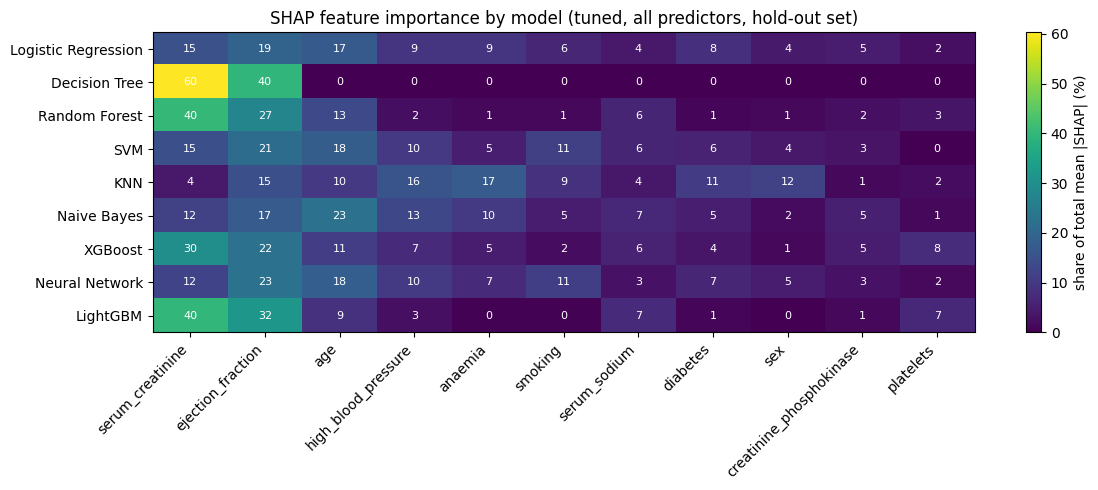

Saved: /kaggle/working/shap_importance_heatmap.png

Mean share of SHAP importance across models (%):
serum_creatinine            25.3
ejection_fraction           24.1
age                         13.2
high_blood_pressure          7.8
anaemia                      6.2
smoking                      5.1
serum_sodium                 4.8
diabetes                     4.7
sex                          3.2
creatinine_phosphokinase     2.8
platelets                    2.8

Detailed SHAP plots for the best model by nested-CV AUC (tuned_all): Random Forest


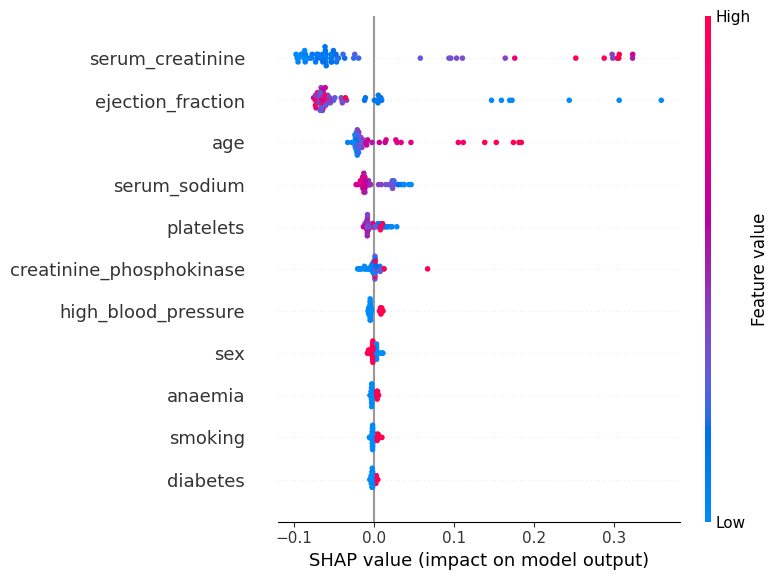

Saved: /kaggle/working/shap_summary_Random_Forest.png


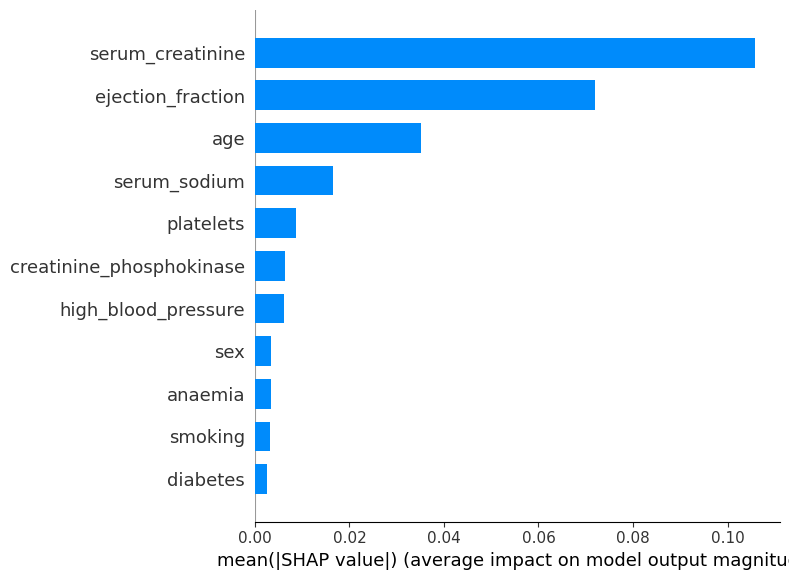

Saved: /kaggle/working/shap_bar_Random_Forest.png


<Figure size 640x480 with 0 Axes>

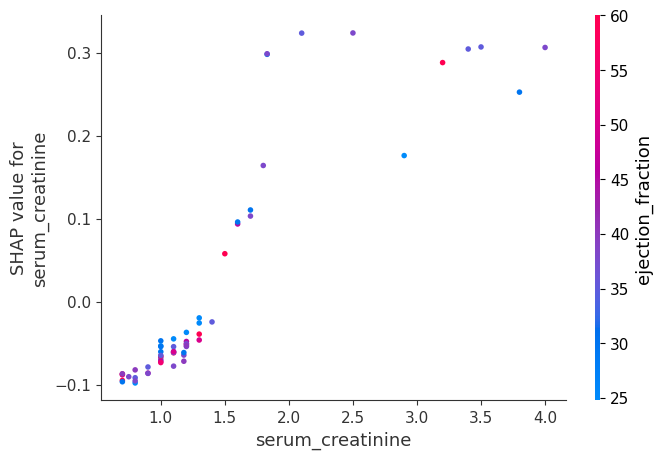

Saved: /kaggle/working/shap_dependence_Random_Forest_serum_creatinine.png

Top-4 by SHAP (Random Forest): ['serum_creatinine', 'ejection_fraction', 'age', 'serum_sodium']
RankSumSelector top-4 (train split): ['serum_creatinine', 'ejection_fraction', 'age', 'anaemia']
SHAP vs RankSum overlap: ['age', 'ejection_fraction', 'serum_creatinine']
Note: SHAP shows what the fitted model relies on; it is not a causal / clinical statement, and with 60 explained rows the ranking is noisy.


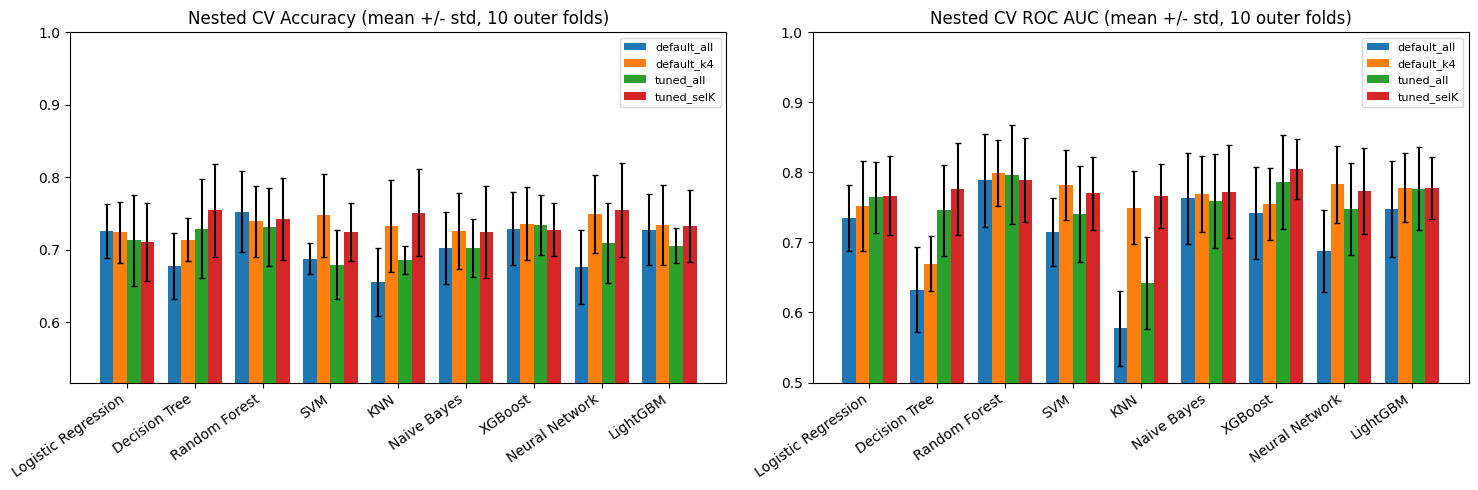

Saved: /kaggle/working/nestedcv_default_vs_tuned.png


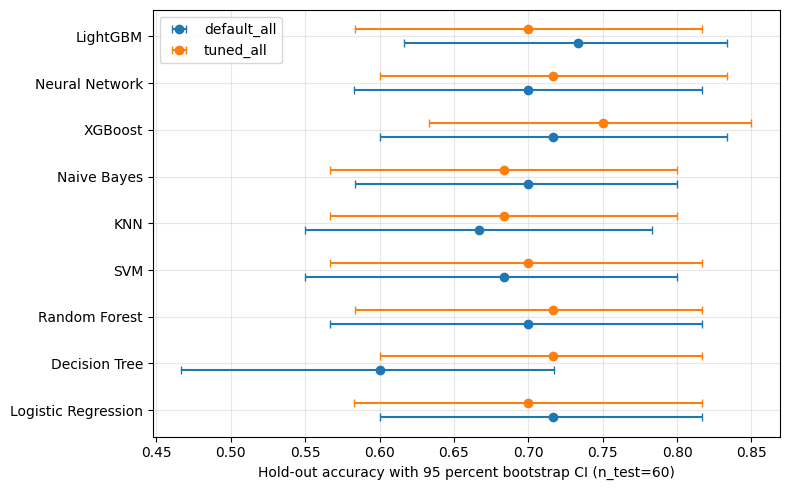

Saved: /kaggle/working/holdout_accuracy_ci.png

SUMMARY
No tuning-effect or selection-effect comparison is significant after Holm correction (alpha=0.05): differences seen above are compatible with noise at this sample size.

Highest nested-CV mean AUC: XGBoost / tuned_selK = 0.8050 +/- 0.0424. Check the Friedman / Nemenyi / Holm tables before calling any model 'best'.

Caveats: the hold-out test has only 60 rows; nested-CV folds overlap in training data so p-values are approximate and power is low (N=10 folds). Search spaces, K_GRID and SHAP settings are my own assumptions.

REFERENCE ONLY: the paper reports about 90% Random Forest accuracy on Faisalabad before feature selection; Table 12 reports 91.67% after selection. The paper does not provide enough split details for a direct apples-to-apples comparison.
   [main CSV saved: 652 rows -> /kaggle/working/faisalabad_main_results.csv]

MAIN RESULTS FILE: /kaggle/working/faisalabad_main_results.csv
Total runtime: 26.7 min. Done.


In [1]:
# =============================================================================
# Faisalabad heart-failure - complete evaluation pipeline: baseline vs OPTIMISED models + STATISTICS + SHAP (XAI)
# (adapted from the original heart-disease evaluation pipeline for Faisalabad)
#
# WHAT THIS SCRIPT DOES
#  1. BASELINE: the same default models/pipelines/split as Part 1 (so numbers can be compared).
#  2. OPTIMISATION: hyper-parameter search per model on the TRAINING split only
#     (5-fold stratified inner CV, RandomizedSearchCV, scoring = ROC AUC). The test split is
#     never used for tuning. In the feature-selection variant the number of selected
#     features K is ALSO tuned inside the inner CV.
#  3. HOLD-OUT EVALUATION on the untouched 20% test split + bootstrap 95% CIs.
#  4. NESTED CROSS-VALIDATION on all de-duplicated rows (repeated stratified 5-fold outer loop,
#     tuning repeated inside every outer-training fold) = the main evidence; the 61-row test
#     split is not.
#  5. STATISTICS on the paired nested-CV fold scores: Nadeau-Bengio corrected paired t-test,
#     Friedman + Nemenyi critical difference, Holm-corrected Wilcoxon vs the best-ranked model,
#     paired bootstrap CIs on the hold-out set.
#  6. SHAP (explainable AI) for every tuned model (11 predictors) on the hold-out set, with detailed
#     plots for the best model (by nested-CV AUC) and a cross-model importance heat-map.
#
# OUTPUT: ONE main CSV  /kaggle/working/faisalabad_main_results.csv
#   The first column "record_type" says what each row is:
#     run_info          settings / data facts (item, value)
#     model_summary     one row per (model, variant): hold-out metrics, bootstrap CIs, nested-CV mean/std,
#                       best hyper-parameters, features used
#     nestedcv_fold     one row per (model, variant, outer fold)
#     stat_test         every statistical test (analysis, comparison, metric, p_value, p_holm, ...)
#     selector_rank     RankSumSelector rank-sum per feature (training split)
#     shap_importance   mean |SHAP| per (model, feature) on the hold-out set
#   (PNG figures are also saved in /kaggle/working/.)
#   The CSV is re-saved after every stage, so a crash late in the run cannot lose earlier results.
#
# HONESTY NOTES
#  - Tuning on ~240 rows often gives small or no gains; the script reports whatever it finds.
#  - Inner-CV best scores are optimistic by construction; only nested-CV / hold-out numbers
#    are reported as performance.
#  - Tests on 10 correlated CV folds have LOW POWER and approximate p-values.
#  - SHAP explains what the MODEL uses, not medical causality; its rankings are noisy on a small hold-out,
#    and SHAP scales differ between model types (so use the % columns to compare).
#  - No tuning on test data, no seed search (RANDOM_STATE = 42 throughout).
# =============================================================================

import os
os.environ["PYTHONWARNINGS"] = "ignore"        # also silences joblib worker processes

import glob
import time
import platform
import traceback
import warnings
from math import prod
from functools import partial

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
from scipy import stats
from scipy.stats import rankdata

import sklearn
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.feature_selection import SelectKBest, chi2, f_classif, mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     RepeatedStratifiedKFold, RandomizedSearchCV)
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier

warnings.filterwarnings("ignore")

# ----------------------------------------------------------------------------
# Configuration
# ----------------------------------------------------------------------------
RANDOM_STATE = 42
QUICK_MODE = False             # True = fast smoke test (fewer repeats / iterations)
K_FEATURES = 4                 # fixed-K baseline, used by the default_k4 variant
TEST_SIZE = 0.20
TUNE_SCORING = "roc_auc"       # smoother / less noisy than accuracy on ~240 rows
INNER_FOLDS = 5
OUTER_FOLDS = 5
OUTER_REPEATS = 2              # 5x2 = 10 paired outer folds
N_ITER = 20                    # random-search budget per model (capped at grid size)
N_BOOT = 1000                  # bootstrap resamples on the hold-out set
K_GRID = [3, 4, 5, 6, 8, 10]   # K values searched in the tuned_selK variant
N_JOBS = -1
ALPHA = 0.05                   # Nemenyi table below is for alpha = 0.05
RUN_SHAP = True
SHAP_BACKGROUND = 15           # background rows for KernelExplainer (SVM / KNN / NB / MLP)
SHAP_NSAMPLES = 300            # KernelExplainer samples per row (approximation, stated in CSV)

if QUICK_MODE:
    OUTER_REPEATS, N_ITER, N_BOOT, SHAP_NSAMPLES = 1, 8, 300, 100

DATA_PATH = "/kaggle/input/datasets/andrewmvd/heart-failure-clinical-data/heart_failure_clinical_records_dataset.csv"  # optionally set the full CSV path; blank = find a compatible Faisalabad CSV in INPUT_ROOT
INPUT_ROOT = "/kaggle/input"
OUT_DIR = "/kaggle/working"
MAIN_CSV = os.path.join(OUT_DIR, "faisalabad_main_results.csv")

FEATURES = ["age", "anaemia", "creatinine_phosphokinase", "diabetes",
            "ejection_fraction", "high_blood_pressure", "platelets",
            "serum_creatinine", "serum_sodium", "sex", "smoking"]  # excludes follow-up duration `time`
TARGET_COLUMN = "death_event"  # 1 = death event during follow-up
# Intentionally excluded: `time` is follow-up duration and may not be known at prediction time.
PAPER_RF_ACC_REFERENCE = 90.00  # paper reports approx. 90% before selection; Table 12 also reports 91.67% after selection
# Nemenyi q(0.05) from Demsar (2006), k = 2..10 classifiers
NEMENYI_Q05 = {2: 1.960, 3: 2.343, 4: 2.569, 5: 2.728, 6: 2.850, 7: 2.949, 8: 3.031, 9: 3.102, 10: 3.164}

os.makedirs(OUT_DIR, exist_ok=True)
np.random.seed(RANDOM_STATE)
T0 = time.time()


def safe_run(label, fn):
    """Run a stage; if it fails, print the traceback and CONTINUE (earlier results are kept)."""
    try:
        return fn()
    except Exception as e:  # noqa
        print(f"\n!!! STAGE FAILED: {label}: {type(e).__name__}: {e}")
        traceback.print_exc()
        return None


print("=" * 78)
print("LIBRARY VERSIONS / SETTINGS")
print("=" * 78)
print("python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scipy", scipy.__version__, "| sklearn", sklearn.__version__)
print("cpu cores:", os.cpu_count(), "| QUICK_MODE:", QUICK_MODE)
XGBClassifier, XGB_SKIP = None, None
try:
    import xgboost
    from xgboost import XGBClassifier
    print("xgboost", xgboost.__version__)
except Exception as e:  # noqa
    XGB_SKIP = f"xgboost import failed: {type(e).__name__}: {e}"
    print("xgboost NOT AVAILABLE ->", XGB_SKIP)
LGBMClassifier, LGBM_SKIP = None, None
try:
    import lightgbm
    from lightgbm import LGBMClassifier
    print("lightgbm", lightgbm.__version__)
except Exception as e:  # noqa
    LGBM_SKIP = f"lightgbm import failed: {type(e).__name__}: {e}"
    print("lightgbm NOT AVAILABLE ->", LGBM_SKIP)
shap = None
SHAP_SKIP = None
if RUN_SHAP:
    try:
        import shap
        print("shap", shap.__version__)
    except Exception as e:  # noqa
        SHAP_SKIP = f"shap import failed: {type(e).__name__}: {e}"
        print("shap NOT AVAILABLE ->", SHAP_SKIP, "(SHAP stage will be skipped)")

# ============================================================================
# DATA (Faisalabad loading, cleaning, and stratified split)
# ============================================================================
print("\n" + "=" * 78)
print("DATA")
print("=" * 78)


def normalize_column_name(name):
    """Normalize common CSV header differences while preserving the dataset fields."""
    return str(name).strip().lower().replace(" ", "_").replace("-", "_")


def find_csv(root=INPUT_ROOT, explicit=DATA_PATH):
    """Find a CSV with all Faisalabad predictor fields and the DEATH_EVENT label."""
    if explicit and os.path.isfile(explicit):
        return explicit
    if explicit:
        print(f"DATA_PATH not found ({explicit}); searching for a compatible CSV.")
    if os.path.isfile(root):
        cands = [root]
    else:
        cands = sorted(glob.glob(os.path.join(root, "**", "*.csv"), recursive=True))
        if not cands and root != "/kaggle/input":
            cands = sorted(glob.glob("/kaggle/input/**/*.csv", recursive=True))
    if not cands:
        raise FileNotFoundError("No CSV found. Add the Faisalabad heart-failure CSV under /kaggle/input or set DATA_PATH.")
    required = set(FEATURES + [TARGET_COLUMN])
    valid = []
    for path in cands:
        try:
            cols = {normalize_column_name(c) for c in pd.read_csv(path, nrows=0).columns}
        except Exception:
            continue
        if required <= cols:
            valid.append(path)
    if not valid:
        raise FileNotFoundError(
            "No CSV has the Faisalabad schema. Required columns: " + ", ".join(FEATURES + [TARGET_COLUMN])
        )
    preferred = [p for p in valid if "heart_failure_clinical_records_dataset" in os.path.basename(p).lower()]
    return (preferred or valid)[0]


data_path = find_csv()
print("USING CSV:", data_path)
raw = pd.read_csv(data_path, na_values=["?", "NA", "N/A", "", " "])
raw.columns = [normalize_column_name(c) for c in raw.columns]
required = FEATURES + [TARGET_COLUMN]
missing_columns = [c for c in required if c not in raw.columns]
if missing_columns:
    raise ValueError(f"Missing required Faisalabad columns: {missing_columns}")

df = raw[required].apply(pd.to_numeric, errors="coerce").copy()
# Drop only rows whose outcome is missing/invalid; predictors are imputed within each training fold.
invalid_target = df[TARGET_COLUMN].isna() | ~df[TARGET_COLUMN].isin([0, 1])
if invalid_target.any():
    print(f"Dropping {int(invalid_target.sum())} rows with missing/non-binary {TARGET_COLUMN}.")
    df = df.loc[~invalid_target].copy()
df[TARGET_COLUMN] = df[TARGET_COLUMN].astype(int)

n_loaded = len(raw)
n_exact_duplicates = int(df.duplicated().sum())
# Keep repeated rows: they may represent distinct patients, and the source provides no patient IDs
# with which to determine whether repeated feature/label rows are duplicate records.
df = df.reset_index(drop=True)
print(f"Rows loaded {n_loaded} -> analysis rows {len(df)}; exact repeated rows retained: {n_exact_duplicates}")
print("Missing predictor values (total):", int(df[FEATURES].isna().sum().sum()))
print("Class balance (DEATH_EVENT):", df[TARGET_COLUMN].value_counts().sort_index().to_dict(),
      "| positive class 1 = death event")
if df[TARGET_COLUMN].nunique() != 2:
    raise ValueError("DEATH_EVENT must contain both binary classes 0 and 1 after cleaning.")
if int(df[TARGET_COLUMN].value_counts().min()) < max(INNER_FOLDS, OUTER_FOLDS):
    raise ValueError("Each target class needs at least as many rows as the CV fold count.")

X, y = df[FEATURES], df[TARGET_COLUMN]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)
print(f"Train {len(X_train)} | Test {len(X_test)} (stratified {100 * (1 - TEST_SIZE):.0f}/{100 * TEST_SIZE:.0f} split)")
y_test_np = y_test.values

# ============================================================================
# Feature selector (training-fold RankSumSelector: rank-sum of chi2 / F / MI, train-only)
# ============================================================================


class RankSumSelector(BaseEstimator, TransformerMixin):
    """Top-k features by summed ranks of chi2, f_classif and mutual_info_classif (1 = best)."""

    def __init__(self, k=4, feature_names=None, random_state=42):
        self.k = k
        self.feature_names = feature_names
        self.random_state = random_state

    def fit(self, X, y):
        Xa = np.asarray(X, dtype=float)
        n = Xa.shape[1]
        names = list(self.feature_names) if self.feature_names is not None else [f"x{i}" for i in range(n)]
        k = min(int(self.k), n)
        fns = {"chi2": chi2, "f": f_classif,
               "mi": partial(mutual_info_classif, random_state=self.random_state)}
        rank_sum = np.zeros(n)
        for fn in fns.values():
            s = np.nan_to_num(np.asarray(SelectKBest(fn, k="all").fit(Xa, y).scores_, float), nan=0.0)
            rank_sum += rankdata(-s, method="average")
        order = np.argsort(rank_sum, kind="stable")
        self.selected_idx_ = order[:k]
        self.selected_features_ = [names[i] for i in self.selected_idx_]
        self.rank_sum_ = dict(zip(names, rank_sum.tolist()))
        self.n_features_in_ = n
        return self

    def transform(self, X):
        return np.asarray(X, dtype=float)[:, self.selected_idx_]


def build_pipeline(model, use_selection):
    steps = [("imputer", SimpleImputer(strategy="median")), ("scaler", MinMaxScaler())]
    if use_selection:
        steps.append(("selector", RankSumSelector(k=K_FEATURES, feature_names=FEATURES,
                                                  random_state=RANDOM_STATE)))
    steps.append(("model", model))
    return Pipeline(steps)


# Reference selection on the training split (for printing / CSV / comparison with SHAP)
ref_sel = build_pipeline(LogisticRegression(max_iter=1000), True).fit(X_train, y_train).named_steps["selector"]
print(f"\nRankSumSelector (K={K_FEATURES}, train split) selected: {ref_sel.selected_features_}")
print("Selected features are ranked from the training split only.")

# ============================================================================
# Models: default factory (identical to Part 1) + search spaces
# ============================================================================


def make_model(name, search=False):
    """search=True only pins tree libraries to 1 thread to avoid CPU over-subscription
    while the search itself runs in parallel. Hyper-parameter defaults are unchanged."""
    rs = RANDOM_STATE
    if name == "Logistic Regression":
        return LogisticRegression(max_iter=1000, random_state=rs)
    if name == "Decision Tree":
        return DecisionTreeClassifier(criterion="entropy", random_state=rs)
    if name == "Random Forest":
        return RandomForestClassifier(n_estimators=100, random_state=rs, n_jobs=1 if search else None)
    if name == "SVM":
        return SVC(kernel="rbf", probability=True, random_state=rs)
    if name == "KNN":
        return KNeighborsClassifier(n_neighbors=5)
    if name == "Naive Bayes":
        return GaussianNB()
    if name == "XGBoost":
        return XGBClassifier(random_state=rs, eval_metric="logloss", n_jobs=1 if search else None)
    if name == "Neural Network":
        return MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=1000, random_state=rs)
    if name == "LightGBM":
        kw = dict(n_jobs=1, subsample_freq=1) if search else {}
        return LGBMClassifier(random_state=rs, verbose=-1, **kw)
    raise KeyError(name)


# Search spaces (my own choices - not from the paper; all are ASSUMPTIONS)
GRIDS = {
    "Logistic Regression": {"C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30, 100],
                            "class_weight": [None, "balanced"]},
    "Decision Tree": {"criterion": ["entropy", "gini"], "max_depth": [2, 3, 4, 5, 6, 8, None],
                      "min_samples_leaf": [1, 2, 5, 10], "min_samples_split": [2, 5, 10],
                      "ccp_alpha": [0.0, 0.005, 0.01, 0.02, 0.04]},
    "Random Forest": {"n_estimators": [100, 200, 300, 500], "max_depth": [None, 3, 5, 8],
                      "min_samples_leaf": [1, 2, 4], "max_features": ["sqrt", "log2", 0.5]},
    "SVM": {"C": [0.1, 0.3, 1, 3, 10, 30, 100], "gamma": ["scale", 0.003, 0.01, 0.03, 0.1, 0.3, 1]},
    "KNN": {"n_neighbors": [3, 5, 7, 9, 11, 15, 21], "weights": ["uniform", "distance"], "p": [1, 2]},
    "Naive Bayes": {"var_smoothing": list(np.logspace(-9, -1, 9))},
    "XGBoost": {"n_estimators": [50, 100, 200, 300], "max_depth": [2, 3, 4, 6],
                "learning_rate": [0.01, 0.03, 0.1, 0.3], "subsample": [0.7, 0.85, 1.0],
                "colsample_bytree": [0.7, 0.85, 1.0], "min_child_weight": [1, 3, 5],
                "reg_lambda": [1, 5, 10]},
    "Neural Network": {"hidden_layer_sizes": [(32,), (64,), (64, 32), (128, 64)],
                       "alpha": [1e-4, 1e-3, 1e-2, 1e-1], "learning_rate_init": [1e-3, 3e-3, 1e-2]},
    "LightGBM": {"n_estimators": [50, 100, 200, 300], "num_leaves": [4, 8, 15, 31],
                 "learning_rate": [0.01, 0.03, 0.1, 0.3], "min_child_samples": [5, 10, 20],
                 "subsample": [0.7, 0.85, 1.0], "colsample_bytree": [0.7, 1.0],
                 "reg_lambda": [0, 1, 5]},
}
SKIP = {"XGBoost": XGB_SKIP, "LightGBM": LGBM_SKIP}
MODEL_NAMES = [m for m in GRIDS if SKIP.get(m) is None]
for _m, _why in SKIP.items():
    if _why:
        print(f"[skip] {_m}: {_why}")

VARIANTS = {                                   # name -> (use_selection, tune)
    "default_all": (False, False),             # baseline, 11 predictors, default settings
    "default_k4": (True, False),               # baseline, fixed K=4 selection
    "tuned_all": (False, True),                # 11 predictors, tuned
    "tuned_selK": (True, True),                # selection with K tuned + model tuned
}
INNER_CV = StratifiedKFold(n_splits=INNER_FOLDS, shuffle=True, random_state=RANDOM_STATE)


def make_estimator(name, variant):
    use_sel, tune = VARIANTS[variant]
    pipe = build_pipeline(make_model(name, search=tune), use_sel)
    if not tune:
        return pipe
    grid = {f"model__{k}": v for k, v in GRIDS[name].items()}
    if use_sel:
        grid["selector__k"] = K_GRID
    size = prod(len(v) for v in grid.values())
    n_iter = min(int(N_ITER * (1.5 if use_sel else 1.0)), size)
    return RandomizedSearchCV(pipe, grid, n_iter=n_iter, scoring=TUNE_SCORING, cv=INNER_CV,
                              n_jobs=N_JOBS, random_state=RANDOM_STATE, refit=True,
                              error_score="raise")


def fitted_pipe(est):
    return est.best_estimator_ if hasattr(est, "best_estimator_") else est


def clean_params(p):
    out = {}
    for k, v in p.items():
        k2 = k.replace("model__", "").replace("selector__", "sel_")
        out[k2] = float(v) if isinstance(v, np.floating) else (int(v) if isinstance(v, np.integer) else v)
    return out


# ----------------------------------------------------------------------------
# Global result containers + the ONE main CSV writer
# ----------------------------------------------------------------------------
hold = pd.DataFrame()          # model_summary rows
folds = pd.DataFrame()         # nestedcv_fold rows
stat_rows = []                 # stat_test rows
shap_rows = []                 # shap_importance rows
hold_pred, hold_fit, boot = {}, {}, {}

RUN_INFO = {
    "data_path": data_path, "rows_loaded": n_loaded, "rows_after_cleaning": len(df), "exact_repeated_rows_retained": n_exact_duplicates,
    "train_size": len(X_train), "test_size": len(X_test), "random_state": RANDOM_STATE,
    "positive_class": "1 (DEATH_EVENT: event occurred)", "tune_scoring": TUNE_SCORING,
    "excluded_predictor": "time (follow-up duration; excluded to avoid potential outcome leakage)",
    "search": f"RandomizedSearchCV n_iter<={N_ITER} (x1.5 for tuned_selK), inner {INNER_FOLDS}-fold",
    "nested_cv": f"outer {OUTER_FOLDS}-fold x {OUTER_REPEATS} repeats", "n_boot": N_BOOT,
    "k_grid": str(K_GRID), "k_default_variant": K_FEATURES, "quick_mode": QUICK_MODE,
    "sklearn": sklearn.__version__, "shap": (shap.__version__ if shap is not None else f"unavailable ({SHAP_SKIP})"),
    "xgboost": "available" if XGBClassifier is not None else f"SKIPPED ({XGB_SKIP})",
    "lightgbm": "available" if LGBMClassifier is not None else f"SKIPPED ({LGBM_SKIP})",
}

MAIN_COLUMNS = [
    "record_type", "model", "variant", "fold", "analysis", "comparison", "metric", "feature", "item", "value",
    "n_features", "features_used", "best_params", "inner_cv_best_auc",
    "accuracy", "precision", "recall", "f1", "specificity", "classification_error", "roc_auc",
    "tn", "fp", "fn", "tp", "acc_ci_low", "acc_ci_high", "auc_ci_low", "auc_ci_high",
    "cv_accuracy_mean", "cv_accuracy_std", "cv_f1_mean", "cv_f1_std", "cv_auc_mean", "cv_auc_std", "n_folds",
    "fold_accuracy", "fold_f1", "fold_auc",
    "mean_diff", "diff_ci_low", "diff_ci_high", "statistic", "p_value", "p_holm", "test_name",
    "rank_sum", "selected_by_ranksum", "mean_abs_shap", "mean_abs_shap_pct", "shap_rank", "shap_method",
    "train_size", "test_size", "random_state", "notes"]


def save_main_csv():
    parts = [pd.DataFrame([dict(record_type="run_info", item=k, value=str(v)) for k, v in RUN_INFO.items()])]
    if len(hold):
        parts.append(hold.assign(record_type="model_summary"))
    if len(folds):
        parts.append(folds.rename(columns={"accuracy": "fold_accuracy", "f1": "fold_f1", "roc_auc": "fold_auc"})
                     .assign(record_type="nestedcv_fold"))
    if stat_rows:
        parts.append(pd.DataFrame(stat_rows).rename(columns={"ci_low": "diff_ci_low", "ci_high": "diff_ci_high",
                                                             "t": "statistic", "p": "p_value", "test": "test_name"})
                     .assign(record_type="stat_test"))
    parts.append(pd.DataFrame(
        [dict(record_type="selector_rank", feature=f, rank_sum=v, selected_by_ranksum=(f in ref_sel.selected_features_),
              notes=f"RankSumSelector fitted on training split; lower rank_sum = better; K={K_FEATURES}")
         for f, v in sorted(ref_sel.rank_sum_.items(), key=lambda kv: kv[1])]))
    if shap_rows:
        parts.append(pd.DataFrame(shap_rows).assign(record_type="shap_importance"))
    out = pd.concat([p for p in parts if len(p)], ignore_index=True, sort=False)
    for c in MAIN_COLUMNS:
        if c not in out.columns:
            out[c] = np.nan
    extra = [c for c in out.columns if c not in MAIN_COLUMNS]
    out = out[MAIN_COLUMNS + extra]
    out.to_csv(MAIN_CSV, index=False)
    print(f"   [main CSV saved: {len(out)} rows -> {MAIN_CSV}]")


# ============================================================================
# PHASE 1+2 - HOLD-OUT: baseline vs tuned (tuning on training split only)
# ============================================================================
print("\n" + "=" * 78)
print("PHASE 1+2 - HOLD-OUT EVALUATION: DEFAULT vs TUNED (tuned on the TRAINING split only)")
print("=" * 78)

holdout_rows = []
for name in MODEL_NAMES:
    for variant, (use_sel, tune) in VARIANTS.items():
        row = dict(model=name, variant=variant, n_features=np.nan, features_used="",
                   best_params="", inner_cv_best_auc=np.nan, notes="")
        try:
            est = make_estimator(name, variant)
            est.fit(X_train, y_train)
            fp = fitted_pipe(est)
            if tune:
                row["best_params"] = str(clean_params(est.best_params_))
                row["inner_cv_best_auc"] = est.best_score_
                row["notes"] = (f"tuned on train only: RandomizedSearchCV n_iter={est.n_iter}, "
                                f"{INNER_FOLDS}-fold CV, scoring={TUNE_SCORING}")
            feats = list(fp.named_steps["selector"].selected_features_) if use_sel else list(FEATURES)
            pred = fp.predict(X_test)
            proba = fp.predict_proba(X_test)[:, 1]
            tn, fpos, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
            acc = accuracy_score(y_test, pred)
            row.update(n_features=len(feats), features_used=";".join(feats), accuracy=acc,
                       precision=precision_score(y_test, pred, zero_division=0),
                       recall=recall_score(y_test, pred, zero_division=0),
                       f1=f1_score(y_test, pred, zero_division=0),
                       specificity=tn / (tn + fpos) if (tn + fpos) else np.nan,
                       classification_error=1 - acc, roc_auc=roc_auc_score(y_test, proba),
                       tn=int(tn), fp=int(fpos), fn=int(fn), tp=int(tp))
            hold_pred[(name, variant)] = (pred, proba)
            hold_fit[(name, variant)] = fp
        except Exception as e:  # noqa
            row["notes"] += f" | HOLD-OUT ERROR: {type(e).__name__}: {e}"
        holdout_rows.append(row)
        extra = f" best={row['best_params']}" if tune and row["best_params"] else ""
        print(f"[{time.time() - T0:6.0f}s] {name:20s} {variant:12s} test_acc={row.get('accuracy', np.nan):.4f} "
              f"auc={row.get('roc_auc', np.nan):.4f}{extra}")
for _m, _why in SKIP.items():
    if _why:
        holdout_rows.append(dict(model=_m, variant="all", notes=f"SKIPPED: {_why}"))
hold = pd.DataFrame(holdout_rows)

# ---- bootstrap CIs on the hold-out set (same resample indices for every variant -> paired) ----
rng = np.random.default_rng(RANDOM_STATE)
BIDX = rng.integers(0, len(y_test_np), size=(N_BOOT, len(y_test_np)))
YB = y_test_np[BIDX]
valid_b = YB.min(axis=1) != YB.max(axis=1)


def boot_arrays(pred, proba):
    acc = (pred[BIDX] == YB).mean(axis=1)
    auc = np.full(N_BOOT, np.nan)
    for b in np.where(valid_b)[0]:
        auc[b] = roc_auc_score(YB[b], proba[BIDX[b]])
    return acc, auc


def add_bootstrap():
    global hold
    for k, v in hold_pred.items():
        boot[k] = boot_arrays(*v)
    for metric, pos in (("acc", 0), ("auc", 1)):
        lo, hi = [], []
        for _, r in hold.iterrows():
            key = (r["model"], r["variant"])
            if key in boot:
                lo_, hi_ = np.nanpercentile(boot[key][pos], [2.5, 97.5])
            else:
                lo_, hi_ = np.nan, np.nan
            lo.append(lo_)
            hi.append(hi_)
        hold[f"{metric}_ci_low"], hold[f"{metric}_ci_high"] = lo, hi


safe_run("bootstrap CIs", add_bootstrap)
hold["train_size"], hold["test_size"], hold["random_state"] = len(X_train), len(X_test), RANDOM_STATE
save_main_csv()

# ============================================================================
# PHASE 3 - NESTED CROSS-VALIDATION (main evidence)
# ============================================================================
print("\n" + "=" * 78)
print(f"PHASE 3 - NESTED CV on all {len(df)} rows: outer {OUTER_FOLDS}-fold x {OUTER_REPEATS} repeats, "
      f"inner {INNER_FOLDS}-fold tuning inside every outer-training fold")
print("=" * 78)
outer = RepeatedStratifiedKFold(n_splits=OUTER_FOLDS, n_repeats=OUTER_REPEATS, random_state=RANDOM_STATE)
SPLITS = list(outer.split(X, y))
N_FOLDS = len(SPLITS)
fold_rows = []
for name in MODEL_NAMES:
    for variant, (use_sel, tune) in VARIANTS.items():
        try:
            for fi, (tr, te) in enumerate(SPLITS):
                est = make_estimator(name, variant)
                est.fit(X.iloc[tr], y.iloc[tr])
                fp = fitted_pipe(est)
                pred = fp.predict(X.iloc[te])
                proba = fp.predict_proba(X.iloc[te])[:, 1]
                fold_rows.append(dict(
                    model=name, variant=variant, fold=fi,
                    accuracy=accuracy_score(y.iloc[te], pred), f1=f1_score(y.iloc[te], pred, zero_division=0),
                    roc_auc=roc_auc_score(y.iloc[te], proba),
                    best_params=str(clean_params(est.best_params_)) if tune else ""))
        except Exception as e:  # noqa
            print(f"   !! {name}/{variant} failed: {type(e).__name__}: {e}")
    print(f"[{time.time() - T0:6.0f}s] nested CV done for {name}")

folds = pd.DataFrame(fold_rows)
summ = folds.groupby(["model", "variant"]).agg(
    cv_accuracy_mean=("accuracy", "mean"), cv_accuracy_std=("accuracy", "std"),
    cv_f1_mean=("f1", "mean"), cv_f1_std=("f1", "std"),
    cv_auc_mean=("roc_auc", "mean"), cv_auc_std=("roc_auc", "std"),
    n_folds=("fold", "count")).reset_index()
hold = hold.merge(summ, on=["model", "variant"], how="left")
save_main_csv()

# ============================================================================
# RESULTS TABLES
# ============================================================================
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", None)
ho = hold[hold["variant"].isin(list(VARIANTS))]


def print_results():
    print("\n" + "=" * 78)
    print(f"RESULT 1 - HOLD-OUT test accuracy / AUC (n_test = {len(X_test)}; "
          f"1 prediction = {100 / len(X_test):.2f} pts)")
    print("=" * 78)
    tab = ho.pivot(index="model", columns="variant", values="accuracy")[list(VARIANTS)].round(4)
    tab_auc = ho.pivot(index="model", columns="variant", values="roc_auc")[list(VARIANTS)].round(4)
    print("Accuracy:\n", tab.to_string())
    print("\nROC AUC:\n", tab_auc.to_string())

    print("\n" + "=" * 78)
    print(f"RESULT 2 - NESTED CV (mean +/- std over {N_FOLDS} outer folds) - the more reliable numbers")
    print("=" * 78)
    for metric, label in (("accuracy", "Accuracy"), ("roc_auc", "ROC AUC")):
        mm = folds.pivot_table(index="model", columns="variant", values=metric, aggfunc="mean")[list(VARIANTS)]
        ss = folds.pivot_table(index="model", columns="variant", values=metric, aggfunc="std")[list(VARIANTS)]
        out = mm.round(4).astype(str) + " +/-" + ss.round(3).astype(str)
        print(f"\n{label}:\n", out.to_string())

    print("\n" + "=" * 78)
    print("RESULT 3 - HOLD-OUT 95% bootstrap CIs (default_all and tuned_all)")
    print("=" * 78)
    ci = ho[ho["variant"].isin(["default_all", "tuned_all"])][
        ["model", "variant", "accuracy", "acc_ci_low", "acc_ci_high", "roc_auc", "auc_ci_low", "auc_ci_high"]]
    print(ci.round(3).to_string(index=False))


safe_run("results tables", print_results)

# ============================================================================
# STATISTICAL ANALYSIS
# ============================================================================


def holm(p):
    p = np.nan_to_num(np.asarray(p, float), nan=1.0)
    order = np.argsort(p)
    adj = np.empty(len(p))
    run = 0.0
    for r, i in enumerate(order):
        run = max(run, (len(p) - r) * p[i])
        adj[i] = min(1.0, run)
    return adj


def scores(model, variant, metric):
    d = folds[(folds.model == model) & (folds.variant == variant)].sort_values("fold")
    return d[metric].values


def corrected_ttest(d, test_frac):
    """Nadeau & Bengio (2003) corrected resampled paired t-test. test_frac = n_test / n_train."""
    d = np.asarray(d, float)
    J = len(d)
    var = d.var(ddof=1)
    se = np.sqrt((1.0 / J + test_frac) * var)
    if se == 0 or not np.isfinite(se):
        return d.mean(), np.nan, (1.0 if d.mean() == 0 else np.nan), d.mean(), d.mean()
    t = d.mean() / se
    p = 2 * stats.t.sf(abs(t), J - 1)
    h = stats.t.ppf(0.975, J - 1) * se
    return d.mean(), t, p, d.mean() - h, d.mean() + h


def run_statistics():
    print("\n" + "=" * 78)
    print("STATISTICAL ANALYSIS (paired over the same nested-CV outer folds)")
    print("=" * 78)
    test_frac = 1.0 / (OUTER_FOLDS - 1)

    # ---- A/B: paired comparisons per model ----------------------------------------------------
    families = [("Tuning effect (all features)", "tuned_all", "default_all"),
                ("Tuning effect (selected features)", "tuned_selK", "default_k4"),
                ("Selection effect (default settings, K=4)", "default_k4", "default_all"),
                ("Selection effect (tuned, K tuned)", "tuned_selK", "tuned_all")]
    for fam, a, b in families:
        for metric in ("accuracy", "roc_auc"):
            recs = []
            for m in MODEL_NAMES:
                sa, sb = scores(m, a, metric), scores(m, b, metric)
                if len(sa) != N_FOLDS or len(sb) != N_FOLDS:
                    continue
                md, t, p, lo, hi = corrected_ttest(sa - sb, test_frac)
                recs.append(dict(analysis=fam, comparison=f"{a} - {b}", metric=metric, model=m,
                                 mean_diff=md, ci_low=lo, ci_high=hi, t=t, p=p))
            if recs:
                adj = holm([r["p"] for r in recs])
                for r, pa in zip(recs, adj):
                    r["p_holm"] = pa
                    r["test"] = "Nadeau-Bengio corrected paired t-test"
                stat_rows.extend(recs)
                print(f"\n{fam} | {a} - {b} | metric = {metric} (positive = first is better)")
                print(pd.DataFrame(recs)[["model", "mean_diff", "ci_low", "ci_high", "p", "p_holm"]]
                      .round(4).to_string(index=False))
    save_main_csv()

    # ---- C: Friedman + Nemenyi + Holm-Wilcoxon across models -----------------------------------
    for variant in ("default_all", "tuned_all"):
        for metric in ("accuracy", "roc_auc"):
            mats = {m: scores(m, variant, metric) for m in MODEL_NAMES if len(scores(m, variant, metric)) == N_FOLDS}
            k = len(mats)
            if k < 3:
                continue
            M = np.column_stack(list(mats.values()))                  # folds x models
            names = list(mats.keys())
            try:
                chi, pf = stats.friedmanchisquare(*[M[:, j] for j in range(k)])
            except Exception:
                chi, pf = np.nan, np.nan
            ranks = np.apply_along_axis(lambda r: rankdata(-r), 1, M)   # rank 1 = best in each fold
            avg = ranks.mean(axis=0)
            q = NEMENYI_Q05.get(k)
            cd = q * np.sqrt(k * (k + 1) / (6.0 * N_FOLDS)) if q is not None else np.nan
            order = np.argsort(avg)
            best = names[order[0]]
            cd_txt = f"{cd:.2f} rank units" if np.isfinite(cd) else "n/a"
            print(f"\n--- Across-model comparison | variant = {variant} | metric = {metric} ---")
            print(f"Friedman chi2 = {chi:.3f}, p = {pf:.4f} (k={k} models, N={N_FOLDS} folds). "
                  f"Nemenyi critical difference (alpha=0.05) = {cd_txt}.")
            recs = []
            for j in order[1:]:
                try:
                    pw = float(stats.wilcoxon(M[:, order[0]], M[:, j]).pvalue)
                except Exception:
                    pw = 1.0
                recs.append(dict(model=names[j], avg_rank=avg[j], rank_gap=avg[j] - avg[order[0]],
                                 mean_diff_vs_best=float((M[:, order[0]] - M[:, j]).mean()), p_wilcoxon=pw))
            adj = holm([r["p_wilcoxon"] for r in recs])
            tbl = [dict(model=best, avg_rank=avg[order[0]], rank_gap=0.0, mean_diff_vs_best=0.0,
                        p_wilcoxon=np.nan, p_holm=np.nan, note="best average rank")]
            for r, pa in zip(recs, adj):
                note = "n/a" if not np.isfinite(cd) else ("within Nemenyi CD" if r["rank_gap"] < cd else "beyond CD")
                tbl.append(dict(model=r["model"], avg_rank=r["avg_rank"], rank_gap=r["rank_gap"],
                                mean_diff_vs_best=r["mean_diff_vs_best"], p_wilcoxon=r["p_wilcoxon"],
                                p_holm=pa, note=note))
            tdf = pd.DataFrame(tbl)
            print(tdf.round(4).to_string(index=False))
            stat_rows.append(dict(analysis="Friedman across models", comparison=variant, metric=metric,
                                  model="ALL", t=chi, p=pf,
                                  test=f"Friedman; Nemenyi CD={cd:.3f}; best average rank={best}"))
            for _, r in tdf.iterrows():
                if r["note"] != "best average rank":
                    stat_rows.append(dict(analysis="Best-ranked vs others (Holm-Wilcoxon)",
                                          comparison=f"{best} vs {r['model']} [{variant}]", metric=metric,
                                          model=r["model"], mean_diff=r["mean_diff_vs_best"], p=r["p_wilcoxon"],
                                          p_holm=r["p_holm"], test="Wilcoxon signed-rank, Holm-adjusted"))
    save_main_csv()

    # ---- D: paired bootstrap on hold-out (tuned_all - default_all) ------------------------------
    print(f"\n--- Hold-out paired bootstrap: tuned_all - default_all (95 percent CI; n_test={len(X_test)}) ---")
    brecs = []
    for m in MODEL_NAMES:
        if (m, "tuned_all") in boot and (m, "default_all") in boot:
            for pos, metric in ((0, "accuracy"), (1, "roc_auc")):
                d = boot[(m, "tuned_all")][pos] - boot[(m, "default_all")][pos]
                lo, hi = np.nanpercentile(d, [2.5, 97.5])
                brecs.append(dict(model=m, metric=metric, mean_diff=np.nanmean(d), ci_low=lo, ci_high=hi,
                                  ci_excludes_0=bool(lo > 0 or hi < 0)))
                stat_rows.append(dict(analysis="Hold-out paired bootstrap", comparison="tuned_all - default_all",
                                      metric=metric, model=m, mean_diff=np.nanmean(d), ci_low=lo, ci_high=hi,
                                      test="percentile bootstrap"))
    if brecs:
        print(pd.DataFrame(brecs).round(4).to_string(index=False))
    save_main_csv()


safe_run("statistical analysis", run_statistics)

# ============================================================================
# SHAP (XAI) - tuned_all pipelines (all Faisalabad predictors), explained on the hold-out set
# ============================================================================
SHAP_STORE = {}          # model -> SHAP matrix (n_test x n_features), positive class (DEATH_EVENT=1)


def to_pos_class(sv):
    """Normalise SHAP output of different explainers / versions to (n_samples, n_features), class 1."""
    if isinstance(sv, list):
        sv = sv[1] if len(sv) > 1 else sv[0]
    sv = np.asarray(sv)
    if sv.ndim == 3:
        sv = sv[:, :, 1] if sv.shape[2] > 1 else sv[:, :, 0]
    return sv


def kernel_shap(mdl, Xtr_t, Xte_t):
    rs = np.random.RandomState(RANDOM_STATE)
    bg = Xtr_t[rs.choice(len(Xtr_t), size=min(SHAP_BACKGROUND, len(Xtr_t)), replace=False)]
    ex = shap.KernelExplainer(lambda d: mdl.predict_proba(d)[:, 1], bg)
    np.random.seed(RANDOM_STATE)
    try:
        sv = ex.shap_values(Xte_t, nsamples=SHAP_NSAMPLES, silent=True)
    except TypeError:
        sv = ex.shap_values(Xte_t, nsamples=SHAP_NSAMPLES)
    return to_pos_class(sv), f"KernelExplainer(bg={len(bg)}, nsamples={SHAP_NSAMPLES}; probability scale)"


def shap_for_model(name, mdl, Xtr_t, Xte_t):
    """Fast exact explainer when possible, KernelExplainer as a fallback."""
    try:
        if name == "Logistic Regression":
            sv = shap.LinearExplainer(mdl, Xtr_t).shap_values(Xte_t)
            return to_pos_class(sv), "LinearExplainer (log-odds scale)"
        if name in ("Random Forest", "Decision Tree"):
            sv = shap.TreeExplainer(mdl).shap_values(Xte_t, check_additivity=False)
            return to_pos_class(sv), "TreeExplainer (probability scale)"
        if name in ("XGBoost", "LightGBM"):
            sv = shap.TreeExplainer(mdl).shap_values(Xte_t)
            return to_pos_class(sv), "TreeExplainer (log-odds scale)"
    except Exception as e:  # noqa
        print(f"   [{name}] fast SHAP explainer failed ({type(e).__name__}: {e}); using KernelExplainer")
    return kernel_shap(mdl, Xtr_t, Xte_t)


def run_shap():
    if shap is None:
        print("\nSHAP stage skipped:", SHAP_SKIP or "RUN_SHAP is False")
        return
    print("\n" + "=" * 78)
    print(f"SHAP - explaining tuned_all pipelines on the {len(X_test)} hold-out rows "
          "(model trained on the training split only)")
    print("=" * 78)
    imp_pct = {}
    for name in MODEL_NAMES:
        key = (name, "tuned_all")
        if key not in hold_fit:
            continue
        try:
            fp = hold_fit[key]
            pre, mdl = fp[:-1], fp.named_steps["model"]
            Xtr_t, Xte_t = np.asarray(pre.transform(X_train)), np.asarray(pre.transform(X_test))
            sv, method = shap_for_model(name, mdl, Xtr_t, Xte_t)
            if sv.shape != (len(X_test), len(FEATURES)):
                raise ValueError(f"unexpected SHAP shape {sv.shape}")
            mean_abs = np.abs(sv).mean(axis=0)
            pct = 100 * mean_abs / mean_abs.sum() if mean_abs.sum() > 0 else mean_abs
            ranks = rankdata(-mean_abs, method="min")
            for j, f in enumerate(FEATURES):
                shap_rows.append(dict(model=name, variant="tuned_all", feature=f, mean_abs_shap=float(mean_abs[j]),
                                      mean_abs_shap_pct=float(pct[j]), shap_rank=int(ranks[j]), shap_method=method,
                                      notes=f"mean |SHAP| over {len(X_test)} hold-out rows"))
            SHAP_STORE[name] = sv
            imp_pct[name] = pd.Series(pct, index=FEATURES)
            top = [FEATURES[j] for j in np.argsort(-mean_abs)[:4]]
            print(f"[{time.time() - T0:6.0f}s] {name:20s} top-4 SHAP features: {top}   ({method})")
        except Exception as e:  # noqa
            print(f"   !! SHAP failed for {name}: {type(e).__name__}: {e}")
    save_main_csv()
    if not SHAP_STORE:
        return

    # ---- cross-model importance heat-map (share of total mean |SHAP|, %) ----
    try:
        H = pd.DataFrame(imp_pct).T[FEATURES]
        order_cols = H.mean(axis=0).sort_values(ascending=False).index
        H = H[order_cols]
        fig, ax = plt.subplots(figsize=(12, 5))
        im = ax.imshow(H.values, aspect="auto", cmap="viridis")
        ax.set_xticks(range(H.shape[1]))
        ax.set_xticklabels(H.columns, rotation=45, ha="right")
        ax.set_yticks(range(H.shape[0]))
        ax.set_yticklabels(H.index)
        for i in range(H.shape[0]):
            for j in range(H.shape[1]):
                ax.text(j, i, f"{H.values[i, j]:.0f}", ha="center", va="center", color="white", fontsize=8)
        plt.colorbar(im, label="share of total mean |SHAP| (%)")
        ax.set_title("SHAP feature importance by model (tuned, all predictors, hold-out set)")
        plt.tight_layout()
        p = os.path.join(OUT_DIR, "shap_importance_heatmap.png")
        plt.savefig(p, dpi=150)
        plt.show()
        plt.close()
        print("Saved:", p)
        print("\nMean share of SHAP importance across models (%):")
        print(H.mean(axis=0).round(1).to_string())
    except Exception as e:  # noqa
        print("SHAP heat-map skipped:", type(e).__name__, e)

    # ---- detailed plots for the best model (highest nested-CV mean AUC, tuned_all) ----
    try:
        cand = summ[(summ.variant == "tuned_all") & (summ.model.isin(list(SHAP_STORE)))]
        best_name = cand.sort_values("cv_auc_mean", ascending=False).iloc[0]["model"]
        sv = SHAP_STORE[best_name]
        Xdf = X_test.reset_index(drop=True)[FEATURES]
        tag = best_name.replace(" ", "_")
        print(f"\nDetailed SHAP plots for the best model by nested-CV AUC (tuned_all): {best_name}")

        plt.figure()
        shap.summary_plot(sv, Xdf, show=False)
        plt.tight_layout()
        p = os.path.join(OUT_DIR, f"shap_summary_{tag}.png")
        plt.savefig(p, dpi=150, bbox_inches="tight")
        plt.show()
        plt.close()
        print("Saved:", p)

        plt.figure()
        shap.summary_plot(sv, Xdf, plot_type="bar", show=False)
        plt.tight_layout()
        p = os.path.join(OUT_DIR, f"shap_bar_{tag}.png")
        plt.savefig(p, dpi=150, bbox_inches="tight")
        plt.show()
        plt.close()
        print("Saved:", p)

        top_feat = FEATURES[int(np.argmax(np.abs(sv).mean(axis=0)))]
        plt.figure()
        shap.dependence_plot(top_feat, sv, Xdf, show=False)
        p = os.path.join(OUT_DIR, f"shap_dependence_{tag}_{top_feat}.png")
        plt.savefig(p, dpi=150, bbox_inches="tight")
        plt.show()
        plt.close()
        print("Saved:", p)

        shap_top4 = [FEATURES[j] for j in np.argsort(-np.abs(sv).mean(axis=0))[:4]]
        print(f"\nTop-4 by SHAP ({best_name}): {shap_top4}")
        print(f"RankSumSelector top-4 (train split): {ref_sel.selected_features_}")
        print("SHAP vs RankSum overlap:", sorted(set(shap_top4) & set(ref_sel.selected_features_)))
        print("Note: SHAP shows what the fitted model relies on; it is not a causal / clinical statement, "
              f"and with {len(X_test)} explained rows the ranking is noisy.")
    except Exception as e:  # noqa
        print("Detailed SHAP plots skipped:", type(e).__name__, e)
        traceback.print_exc()


safe_run("SHAP", run_shap)

# ============================================================================
# PLOTS
# ============================================================================


def make_plots():
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    for ax, metric, ttl in zip(axes, ("accuracy", "roc_auc"), ("Accuracy", "ROC AUC")):
        w = 0.2
        for i, v in enumerate(VARIANTS):
            mu = [folds[(folds.model == m) & (folds.variant == v)][metric].mean() for m in MODEL_NAMES]
            sd = [folds[(folds.model == m) & (folds.variant == v)][metric].std() for m in MODEL_NAMES]
            ax.bar(np.arange(len(MODEL_NAMES)) + (i - 1.5) * w, mu, w, yerr=sd, capsize=2, label=v)
        ax.set_xticks(np.arange(len(MODEL_NAMES)))
        ax.set_xticklabels(MODEL_NAMES, rotation=35, ha="right")
        ax.set_title(f"Nested CV {ttl} (mean +/- std, {N_FOLDS} outer folds)")
        ax.set_ylim(max(0.5, folds[metric].min() - 0.05), 1.0)
        ax.legend(fontsize=8)
    plt.tight_layout()
    p = os.path.join(OUT_DIR, "nestedcv_default_vs_tuned.png")
    plt.savefig(p, dpi=150)
    plt.show()
    plt.close()
    print("Saved:", p)

    fig, ax = plt.subplots(figsize=(8, 5))
    yy = np.arange(len(MODEL_NAMES))
    for off, v in ((-0.15, "default_all"), (0.15, "tuned_all")):
        sub = ho[ho.variant == v].set_index("model").reindex(MODEL_NAMES)
        ax.errorbar(sub["accuracy"], yy + off,
                    xerr=[sub["accuracy"] - sub["acc_ci_low"], sub["acc_ci_high"] - sub["accuracy"]],
                    fmt="o", capsize=3, label=v)
    ax.set_yticks(yy)
    ax.set_yticklabels(MODEL_NAMES)
    ax.set_xlabel(f"Hold-out accuracy with 95 percent bootstrap CI (n_test={len(X_test)})")
    ax.legend()
    ax.grid(alpha=0.3)
    plt.tight_layout()
    p = os.path.join(OUT_DIR, "holdout_accuracy_ci.png")
    plt.savefig(p, dpi=150)
    plt.show()
    plt.close()
    print("Saved:", p)


safe_run("plots", make_plots)

# ============================================================================
# HONEST SUMMARY (generated from the results above) + final save
# ============================================================================


def print_summary():
    print("\n" + "=" * 78)
    print("SUMMARY")
    print("=" * 78)
    sdf = pd.DataFrame(stat_rows)
    if len(sdf) and "p_holm" in sdf.columns:
        mask = sdf["analysis"].str.contains("Tuning effect|Selection effect", na=False) & (sdf["p_holm"] < ALPHA)
        sig = sdf[mask]
    else:
        sig = pd.DataFrame()
    if len(sig):
        print(f"Paired comparisons significant after Holm correction (alpha={ALPHA}): {len(sig)}")
        print(sig[["analysis", "metric", "model", "mean_diff", "p_holm"]].round(4).to_string(index=False))
    else:
        print(f"No tuning-effect or selection-effect comparison is significant after Holm correction "
              f"(alpha={ALPHA}): differences seen above are compatible with noise at this sample size.")
    best_row = summ.sort_values("cv_auc_mean", ascending=False).iloc[0]
    print(f"\nHighest nested-CV mean AUC: {best_row['model']} / {best_row['variant']} "
          f"= {best_row['cv_auc_mean']:.4f} +/- {best_row['cv_auc_std']:.4f}. "
          "Check the Friedman / Nemenyi / Holm tables before calling any model 'best'.")
    print(f"\nCaveats: the hold-out test has only {len(X_test)} rows; nested-CV folds overlap in training data so p-values are approximate and power is "
          f"low (N={N_FOLDS} folds). Search spaces, K_GRID and SHAP settings are my own assumptions.")
    print(f"\nREFERENCE ONLY: the paper reports about {PAPER_RF_ACC_REFERENCE:.0f}% Random Forest accuracy on Faisalabad before feature selection; Table 12 reports 91.67% after selection. The paper does not provide enough split details for a direct apples-to-apples comparison.")


safe_run("summary", print_summary)
save_main_csv()
print("\nMAIN RESULTS FILE:", MAIN_CSV)
print(f"Total runtime: {(time.time() - T0) / 60:.1f} min. Done.")

**Now From here the SMOTE **